# QUESTION 5 — LE SPECTATEUR CONSOMMERA-T-IL AU BAR ?

**Objectif :** Prédire si un spectateur consommera au bar à partir des informations disponibles au moment de l'achat de son billet.

**Méthode :** Classification supervisée — K-Nearest Neighbors (KNN)

### 1. Chargement des données

In [1]:
#importation des bibliothèques

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement des données nettoyées

billets = pd.read_csv("../data/processed/billets_clean.csv")
evenements = pd.read_csv("../data/processed/evenements_clean.csv",parse_dates=['date'])

# Vérification des dimensions

print("billets:",billets.shape)
print("evenements:",evenements.shape)

# Aperçu des données

billets.head()



billets: (700, 15)
evenements: (96, 9)


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante,age_inconnu,prix_plancher,invitation
0,BL600680,EV369,loge,73.66,53.0,23.0,16.6,-13.5,28.63,41.0,False,True,False,False,False
1,BL600471,EV386,fosse,122.64,44.0,56.0,0.7,-1.7,10.63,44.0,False,False,False,False,False
2,BL600421,EV313,gradin bas,59.81,29.0,34.0,-10.3,-21.7,3.01,32.0,False,False,False,False,False
3,BL600643,EV342,gradin bas,86.22,33.0,32.0,12.9,21.4,4.71,42.0,False,False,False,False,False
4,BL600447,EV388,gradin haut,67.45,102.0,81.0,-35.3,42.9,NaN,30.0,True,True,False,False,False


### 1.1 Vérification de la structure des données

In [2]:
# Informations générales sur les billets
billets.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   billet_id                700 non-null    str    
 1   evenement_id             700 non-null    str    
 2   zone                     700 non-null    str    
 3   prix_paye_eur            700 non-null    float64
 4   achat_jours_avant        700 non-null    float64
 5   arrivee_min_avant        700 non-null    float64
 6   x_salle_m                700 non-null    float64
 7   y_salle_m                700 non-null    float64
 8   conso_bar_eur            686 non-null    float64
 9   age                      700 non-null    float64
 10  deja_venu                700 non-null    bool   
 11  revient_saison_suivante  700 non-null    bool   
 12  age_inconnu              700 non-null    bool   
 13  prix_plancher            700 non-null    bool   
 14  invitation               700 non-null

### 2. Définition de la variable cible

La question 5 est un problème de classification binaire.
À partir de la variable `conso_bar_eur`, nous définissons
une nouvelle variable cible `conso_bar` :

- 0 : le spectateur ne consomme pas au bar.
- 1 : le spectateur consomme au bar.

Les observations dont la consommation au bar est inconnue
sont exclues de l'apprentissage et de l'évaluation du modèle
afin d'éviter l'attribution artificielle d'une classe.

Cette opération concerne 14 billets sur 700 (2 %).

### 2.1 Traitement des valeurs manquantes de consommation au bar

In [3]:
# Nombre de valeurs manquantes avant

print("Consommations inconnues avant :", billets['conso_bar_eur'].isnull().sum())

# Copie sans les billets dont la consommation est inconnue
# (un NaN n'est pas un 0 : décision de l'audit)

billets_q5 = billets.dropna(subset=['conso_bar_eur']).copy()

# Vérifications après suppression

print("Consommations inconnues après :", billets_q5['conso_bar_eur'].isnull().sum())  
print("Nombre de billets :", len(billets_q5))                                         

Consommations inconnues avant : 14
Consommations inconnues après : 0
Nombre de billets : 686


### 2.2 Création de la variable cible binaire

In [4]:
# Création de la variable cible binaire

billets_q5['conso_bar'] = (billets_q5['conso_bar_eur']>0).astype(int)

# Vérification de la variable cible

billets_q5[['conso_bar_eur','conso_bar']].head(10)

,conso_bar_eur,conso_bar
0,28.63,1
1,10.63,1
2,3.01,1
3,4.71,1
5,12.61,1
6,12.38,1
7,7.47,1
8,0.00,0
9,8.07,1
10,7.01,1


### 2.3 Analyse de la distribution de la variable cible

In [5]:
# Nombre de consommateurs et de non-consommateurs

effectifs = billets_q5['conso_bar'].value_counts().sort_index()

# Pourcentage de chaque classe

Pourcentage = billets_q5['conso_bar'].value_counts(normalize=True).sort_index() *100

# Création d'un tableau récapitulatif

distribution=pd.DataFrame({
    'effectifs':effectifs,
    'Pourcentage (%)':Pourcentage.round(2)
})
display(distribution)



,effectifs,Pourcentage (%)
conso_bar,,
0,72,10.5
1,614,89.5


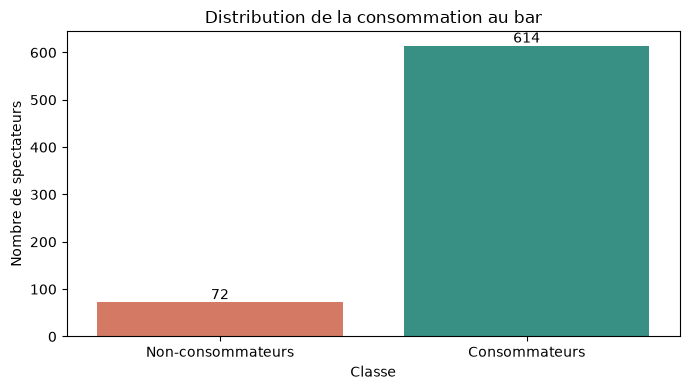

In [6]:
# Visualisation de la distribution des classes
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=billets_q5,
    x='conso_bar',
    hue='conso_bar',
    palette=['#E76F51', '#2A9D8F'],
    legend=False
)

# Affichage des effectifs sur les barres
for container in ax.containers:
    ax.bar_label(container)

plt.title('Distribution de la consommation au bar')
plt.xticks([0, 1], ['Non-consommateurs', 'Consommateurs'])
plt.xlabel('Classe')
plt.ylabel('Nombre de spectateurs')
plt.tight_layout()
plt.show()

**Interprétation :**

La distribution de la variable cible révèle un déséquilibre
important entre les deux classes :

- Classe 0 : 72 non-consommateurs (10,50 %).
- Classe 1 : 614 consommateurs (89,50 %).

Ce déséquilibre peut favoriser la classe majoritaire lors
de l'apprentissage du modèle KNN. L'accuracy seule ne sera
donc pas suffisante pour évaluer ses performances.

Nous utiliserons notamment la précision, le rappel,
le F1-score et la matrice de confusion.

### 3. Sélection des variables prédictives

La sélection des variables repose sur les informations
disponibles au moment de l'achat du billet afin d'éviter
toute fuite de données (Data Leakage).

### 3.1 Analyse des variables événementielles

In [7]:
# Informations générales sur les événements
evenements.info()

# Aperçu des données événementielles
display(evenements.head())

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   evenement_id       96 non-null     str           
 1   genre              96 non-null     str           
 2   jour_semaine       96 non-null     str           
 3   capacite           96 non-null     int64         
 4   prix_moyen_eur     96 non-null     float64       
 5   notoriete_artiste  96 non-null     float64       
 6   billets_vendus     93 non-null     float64       
 7   date               96 non-null     datetime64[us]
 8   taux_remplissage   93 non-null     float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(3)
memory usage: 6.9 KB


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date,taux_remplissage
0,EV320,rap,dim,9800,18.00,26.0,4923.0,2025-11-20,0.502347
1,EV370,spectacle,mar,15800,74.23,20.0,6051.0,2026-06-08,0.382975
2,EV377,sport,sam,6500,45.99,53.0,5221.0,2026-07-06,0.803231
3,EV362,rap,ven,9800,70.96,41.0,6203.0,2026-05-07,0.632959
4,EV394,sport,dim,9800,46.33,100.0,7196.0,2026-09-12,0.734286


### 3.1.1 Vérification de la cohérence des données temporelles

In [8]:
# Calcul du jour à partir de la date
jours_calcules = evenements['date'].dt.day_name().map({
    'Monday': 'lun',
    'Tuesday': 'mar',
    'Wednesday': 'mer',
    'Thursday': 'jeu',
    'Friday': 'ven',
    'Saturday': 'sam',
    'Sunday': 'dim'
})
# Vérification des incohérences
incoherences = evenements['jour_semaine'] != jours_calcules

print("Nombre d'incohérences :", incoherences.sum())
print("Nombre d'événements :", len(evenements))

Nombre d'incohérences : 79
Nombre d'événements : 96


**Interprétation :**

La vérification révèle 79 incohérences sur 96 événements
(82,29 %) entre la date et le jour de la semaine renseigné.

Conformément aux conclusions de l'audit général du projet,
la variable `jour_semaine` est privilégiée en raison de
sa répartition plus réaliste pour une salle de spectacle.

Nous allons étudier sa pertinence pour la prédiction
de la consommation au bar avant de décider de son
intégration au modèle KNN.

### 3.2 Jointure des billets et des événements

La jointure permet d'enrichir les données des billets
avec les caractéristiques des événements, en utilisant
la clé commune `evenement_id`.

Seules les informations supposées disponibles au moment
de l'achat sont retenues afin d'éviter les fuites de données.

In [9]:
# Sélection des variables événementielles
variables_evenements = [
    'evenement_id',
    'genre',
    'jour_semaine',
    'capacite',
    'notoriete_artiste'
]

# Jointure des deux DataFrames
donnees_q5 = billets_q5.merge(
    evenements[variables_evenements],
    on='evenement_id',
    how='left',
    validate='many_to_one'
)

# Vérification des dimensions
print("Dimensions avant jointure :", billets_q5.shape)
print("Dimensions après jointure :", donnees_q5.shape)

# Aperçu des données fusionnées
display(donnees_q5.head())

Dimensions avant jointure : (686, 16)
Dimensions après jointure : (686, 20)


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante,age_inconnu,prix_plancher,invitation,conso_bar,genre,jour_semaine,capacite,notoriete_artiste
0,BL600680,EV369,loge,73.66,53.0,23.0,16.6,-13.5,28.63,41.0,False,True,False,False,False,1,rock,ven,9800,22.0
1,BL600471,EV386,fosse,122.64,44.0,56.0,0.7,-1.7,10.63,44.0,False,False,False,False,False,1,rock,sam,9800,94.0
2,BL600421,EV313,gradin bas,59.81,29.0,34.0,-10.3,-21.7,3.01,32.0,False,False,False,False,False,1,rock,dim,9800,7.0
3,BL600643,EV342,gradin bas,86.22,33.0,32.0,12.9,21.4,4.71,42.0,False,False,False,False,False,1,concert pop,dim,15800,22.0
4,BL600127,EV300,fosse,64.94,92.0,39.0,-5.9,-15.4,12.61,35.0,True,True,True,False,False,1,rock,jeu,9800,45.0


### 3.2.1 Vérification de la jointure

In [10]:
# Vérification des valeurs manquantes après la jointure
donnees_q5[variables_evenements].isnull().sum()

evenement_id         0
genre                0
jour_semaine         0
capacite             0
notoriete_artiste    0
dtype: int64

**Interprétation :**

La jointure a permis d'enrichir les 686 billets avec quatre
variables événementielles, sans perte ni duplication
d'observations et sans introduction de valeurs manquantes
dans les variables ajoutées.

### 3.2.2 Analyse de la consommation au bar selon le jour de la semaine

In [11]:
# Analyse de la consommation au bar selon le jour
conso_par_jour = donnees_q5.groupby('jour_semaine')['conso_bar'].agg(
    ['count', 'sum', 'mean']
)

# Renommage des colonnes
conso_par_jour.columns = [
    'Nombre de billets',
    'Nombre de consommateurs',
    'Taux de consommation (%)'
]

# Conversion du taux en pourcentage
conso_par_jour['Taux de consommation (%)'] *= 100

# Affichage des résultats
display(conso_par_jour.round(2))

,Nombre de billets,Nombre de consommateurs,Taux de consommation (%)
jour_semaine,,,
dim,70,60,85.71
jeu,126,106,84.13
mar,49,46,93.88
mer,82,75,91.46
sam,221,202,91.40
ven,138,125,90.58


**Interprétation :**

Le taux de consommation au bar varie entre 84,13 %
le jeudi et 93,88 % le mardi, soit un écart de
9,75 points de pourcentage.

Toutefois, le taux élevé du mardi doit être interprété
avec prudence en raison de son faible effectif
(49 billets).

Ces résultats suggèrent un intérêt prédictif potentiel
de la variable `jour_semaine`. Elle est donc retenue
provisoirement, puis son utilité sera évaluée en comparant
les performances du KNN avec et sans cette variable
par validation croisée.

### 3.3 Sélection et justification des variables prédictives

Les variables prédictives sont sélectionnées selon leur
pertinence pour la consommation au bar et leur disponibilité
au moment de l'achat du billet.

Les identifiants, les informations futures et les variables
susceptibles de provoquer une fuite de données sont exclus.
Une première sélection limite également les variables
potentiellement redondantes.

In [12]:
# Variables prédictives numériques
variables_numeriques = [
    'prix_paye_eur',
    'achat_jours_avant',
    'age',
    'notoriete_artiste'
]

# Variables prédictives catégorielles
variables_categorielles = [
    'zone',
    'genre',
    'jour_semaine',
    'capacite'
]

# Variables prédictives booléennes
variables_booleennes = [
    'deja_venu',
    'invitation'
]

# Regroupement des variables prédictives
variables_predictives = (
    variables_numeriques
    + variables_categorielles
    + variables_booleennes
)

# Vérification des variables sélectionnées
print("Nombre de variables numériques :", len(variables_numeriques))
print("Nombre de variables catégorielles :", len(variables_categorielles))
print("Nombre de variables booléennes :", len(variables_booleennes))
print("Nombre total de variables prédictives :", len(variables_predictives))

display(donnees_q5[variables_predictives].head())

Nombre de variables numériques : 4
Nombre de variables catégorielles : 4
Nombre de variables booléennes : 2
Nombre total de variables prédictives : 10


,prix_paye_eur,achat_jours_avant,age,notoriete_artiste,zone,genre,jour_semaine,capacite,deja_venu,invitation
0,73.66,53.0,41.0,22.0,loge,rock,ven,9800,False,False
1,122.64,44.0,44.0,94.0,fosse,rock,sam,9800,False,False
2,59.81,29.0,32.0,7.0,gradin bas,rock,dim,9800,False,False
3,86.22,33.0,42.0,22.0,gradin bas,concert pop,dim,15800,False,False
4,64.94,92.0,35.0,45.0,fosse,rock,jeu,9800,True,False


La variable `capacite` est traitée comme une variable
catégorielle, car elle représente trois configurations
distinctes de la salle (6 500, 9 800 et 15 800 places),
conformément aux conclusions de l'audit général.

### 3.4 Justification des variables exclues

Seules les informations disponibles au moment de l'achat
du billet et jugées pertinentes sont retenues pour
la construction du modèle.

| Variable exclue | Justification |
|---|---|
| `billet_id` | Identifiant unique sans intérêt prédictif direct. |
| `evenement_id` | Identifiant utilisé pour la jointure et la validation groupée. |
| `arrivee_min_avant` | Information connue uniquement le jour de l'événement. |
| `revient_saison_suivante` | Information future, indisponible au moment de l'achat. |
| `conso_bar_eur` | Utilisée pour construire la variable cible. Son inclusion provoquerait une fuite de données. |
| `x_salle_m` | Position spatiale partiellement représentée par la variable zone. |
| `y_salle_m` | Position spatiale partiellement représentée par la variable zone. |
| `age_inconnu` | Indicateur technique issu du prétraitement, non retenu. |
| `prix_plancher` | Indicateur dérivé du prix payé, déjà intégré au modèle. |
| `billets_vendus` | Nombre final de billets vendus, non disponible au moment de l'achat. |
| `taux_remplissage` | Indicateur final de remplissage, indisponible au moment de l'achat. |
| `prix_moyen_eur` | Non retenu au profit du prix effectivement payé par le spectateur. |
| `date` | L'information calendaire est partiellement représentée par jour_semaine. |

Cette sélection vise à limiter les fuites de données
et à réduire la complexité du modèle KNN.

### 4. Définition des variables X et y

- X : ensemble des variables prédictives sélectionnées.
- y : variable cible binaire `conso_bar` à prédire.

In [13]:
# Définition des variables prédictives
X = donnees_q5[variables_predictives].copy()

# Définition de la variable cible
y = donnees_q5['conso_bar'].copy()

# Vérification des dimensions
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (686, 10)
Dimensions de y : (686,)


### 4.1 Vérification des données avant l'apprentissage

In [14]:
# Vérification des valeurs manquantes dans X
print("Valeurs manquantes dans X :", X.isnull().sum().sum())

# Vérification des valeurs manquantes dans y
print("Valeurs manquantes dans y :", y.isnull().sum())

# Vérification des classes de la variable cible
print("Classes de y :", sorted(y.unique().tolist()))

Valeurs manquantes dans X : 0
Valeurs manquantes dans y : 0
Classes de y : [0, 1]


### 5. Séparation des données d'entraînement et de test

Les données sont réparties en deux ensembles :

- 80 % pour l'entraînement du modèle.
- 20 % pour l'évaluation finale.

Une séparation stratifiée est utilisée afin de préserver
la proportion des classes dans les deux ensembles,
compte tenu du déséquilibre de la variable cible.

In [15]:
# Importation de la fonction de séparation des données
from sklearn.model_selection import train_test_split

# Séparation des données d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Vérification des dimensions
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)
print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test :", y_test.shape)

Dimensions de X_train : (548, 10)
Dimensions de X_test : (138, 10)
Dimensions de y_train : (548,)
Dimensions de y_test : (138,)


### 5.1 Vérification de la répartition des classes

In [16]:
# Comparaison de la distribution des classes
distribution_classes = pd.DataFrame({
    'Ensemble initial (%)': y.value_counts(normalize=True) * 100,
    'Entraînement (%)': y_train.value_counts(normalize=True) * 100,
    'Test (%)': y_test.value_counts(normalize=True) * 100
}).sort_index()

# Affichage des résultats
display(distribution_classes.round(2))

,Ensemble initial (%),Entraînement (%),Test (%)
conso_bar,,,
0,10.5,10.58,10.14
1,89.5,89.42,89.86


**Interprétation :**

La séparation stratifiée permet de conserver des proportions
de classes similaires dans les ensembles d'entraînement
et de test.

Le déséquilibre initial est préservé, avec environ 90 %
de consommateurs et 10 % de non-consommateurs.

### 6. Encodage et standardisation des variables

Le modèle KNN repose sur le calcul des distances entre
les observations. Il est donc nécessaire de standardiser
les variables numériques et d'encoder les variables
catégorielles afin de rendre les données exploitables
par le modèle.

### 6.1 Standardisation des variables numériques

La standardisation avec `StandardScaler` permet de centrer
les variables numériques et de réduire les différences
d'échelle afin d'éviter qu'une variable ne domine le calcul
des distances du KNN.

Les paramètres de standardisation sont calculés uniquement
à partir des données d'entraînement.

In [17]:
# Importation de StandardScaler
from sklearn.preprocessing import StandardScaler

# Initialisation du standardiseur
scaler = StandardScaler()

# Standardisation des variables numériques d'entraînement
X_train_num = scaler.fit_transform(
    X_train[variables_numeriques]
)

# Standardisation des variables numériques de test
X_test_num = scaler.transform(
    X_test[variables_numeriques]
)

# Conversion des résultats en DataFrames
X_train_num = pd.DataFrame(
    X_train_num,
    columns=variables_numeriques,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    X_test_num,
    columns=variables_numeriques,
    index=X_test.index
)

# Aperçu des données standardisées
print("Données d'entraînement :")
display(X_train_num.head())

print("Données de test :")
display(X_test_num.head())

Données d'entraînement :


,prix_paye_eur,achat_jours_avant,age,notoriete_artiste
162,0.369381,-0.749965,-1.375606,-0.288233
231,-0.433161,-0.749965,0.743636,-1.123403
338,0.640315,-1.247400,-0.492588,0.720931
437,0.599595,-0.849452,-1.199003,-1.019007
412,-0.514281,0.410717,-1.375606,0.024956


Données de test :


,prix_paye_eur,achat_jours_avant,age,notoriete_artiste
173,-0.857357,-1.181075,1.096843,0.546938
584,-1.346962,-0.352017,0.920240,0.546938
128,0.348219,-0.683640,1.273447,-0.775416
679,-1.597375,1.239775,0.037222,1.938888
588,0.219325,-0.915776,-0.051080,-0.114239


### 6.1.1 Vérification de la standardisation

In [18]:
# Comparaison statistique avant et après standardisation
verification_standardisation = pd.DataFrame({
    'Moyenne avant (Train)': X_train[variables_numeriques].mean(),
    'Écart-type avant (Train)': X_train[variables_numeriques].std(ddof=0),
    'Moyenne après (Train)': X_train_num.mean(),
    'Écart-type après (Train)': X_train_num.std(ddof=0),
    'Moyenne après (Test)': X_test_num.mean(),
    'Écart-type après (Test)': X_test_num.std(ddof=0)
})

display(verification_standardisation.round(4))

,Moyenne avant (Train),Écart-type avant (Train),Moyenne après (Train),Écart-type après (Train),Moyenne après (Test),Écart-type après (Test)
prix_paye_eur,70.3296,31.1884,0.0,1.0,-0.0897,0.9080
achat_jours_avant,41.6150,30.1547,0.0,1.0,0.0164,1.1223
age,35.5785,11.3248,0.0,1.0,0.0603,1.0881
notoriete_artiste,44.2828,28.7366,-0.0,1.0,-0.0283,0.9937


**Interprétation :**

Après standardisation, les variables numériques du jeu
d'entraînement présentent une moyenne proche de 0 et
un écart-type égal à 1.

Les données de test sont transformées à partir des paramètres
calculés sur le jeu d'entraînement, ce qui explique les
légères différences observées.

Cette démarche réduit les différences d'échelle entre
les variables numériques tout en évitant les fuites de
données liées à la standardisation.

### 6.2 Encodage des variables catégorielles

L'encodage One-Hot permet de transformer les variables
catégorielles en colonnes binaires sans introduire
d'ordre artificiel entre les modalités.

L'encodeur est ajusté uniquement sur les données
d'entraînement, puis appliqué aux données de test.

In [19]:
# Importation de OneHotEncoder
from sklearn.preprocessing import OneHotEncoder

# Initialisation de l'encodeur
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Encodage des variables catégorielles d'entraînement
X_train_cat = encoder.fit_transform(
    X_train[variables_categorielles]
)

# Encodage des variables catégorielles de test
X_test_cat = encoder.transform(
    X_test[variables_categorielles]
)

# Récupération des noms des nouvelles colonnes
colonnes_encodees = encoder.get_feature_names_out(
    variables_categorielles
)

# Conversion des résultats en DataFrames
X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=colonnes_encodees,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=colonnes_encodees,
    index=X_test.index
)

# Aperçu des données encodées
print("Données d'entraînement :")
display(X_train_cat.head())

print("Données de test :")
display(X_test_cat.head())

Données d'entraînement :


,zone_fosse,zone_gradin bas,zone_gradin haut,zone_loge,genre_concert pop,genre_humour,genre_rap,genre_rock,genre_spectacle,genre_sport,jour_semaine_dim,jour_semaine_jeu,jour_semaine_mar,jour_semaine_mer,jour_semaine_sam,jour_semaine_ven,capacite_6500,capacite_9800,capacite_15800
162,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
231,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
338,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
437,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
412,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Données de test :


,zone_fosse,zone_gradin bas,zone_gradin haut,zone_loge,genre_concert pop,genre_humour,genre_rap,genre_rock,genre_spectacle,genre_sport,jour_semaine_dim,jour_semaine_jeu,jour_semaine_mar,jour_semaine_mer,jour_semaine_sam,jour_semaine_ven,capacite_6500,capacite_9800,capacite_15800
173,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
584,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
128,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
679,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
588,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


### 6.2.1 Vérification de l'encodage

In [20]:
# Nombre de catégories pour chaque variable
for variable, categories in zip(
    variables_categorielles, encoder.categories_
):
    print(variable, ":", len(categories), "catégories")
    print("Modalités :", categories.tolist())
    print()

# Vérification des dimensions après encodage
print("Dimensions avant encodage (Train) :",
      X_train[variables_categorielles].shape)

print("Dimensions après encodage (Train) :", X_train_cat.shape)

print("Dimensions avant encodage (Test) :",
      X_test[variables_categorielles].shape)

print("Dimensions après encodage (Test) :", X_test_cat.shape)

# Vérification de la correspondance des colonnes
print("Colonnes identiques :", 
      X_train_cat.columns.equals(X_test_cat.columns))

zone : 4 catégories
Modalités : ['fosse', 'gradin bas', 'gradin haut', 'loge']

genre : 6 catégories
Modalités : ['concert pop', 'humour', 'rap', 'rock', 'spectacle', 'sport']

jour_semaine : 6 catégories
Modalités : ['dim', 'jeu', 'mar', 'mer', 'sam', 'ven']

capacite : 3 catégories
Modalités : [6500, 9800, 15800]

Dimensions avant encodage (Train) : (548, 4)
Dimensions après encodage (Train) : (548, 19)
Dimensions avant encodage (Test) : (138, 4)
Dimensions après encodage (Test) : (138, 19)
Colonnes identiques : True


**Interprétation :**

L'encodage One-Hot transforme les quatre variables
catégorielles en 19 colonnes binaires.

Les ensembles d'entraînement et de test possèdent
les mêmes colonnes, dans le même ordre, sans perte
d'observations.

Cette transformation permet au KNN d'exploiter les
variables catégorielles sans introduire d'ordre
artificiel entre leurs modalités.

### 6.3 Traitement des variables booléennes

Les variables booléennes sont converties en valeurs
binaires (0 et 1) afin d'être directement exploitables
dans le calcul des distances du KNN.

In [21]:
# Conversion des variables booléennes d'entraînement
X_train_bool = X_train[variables_booleennes].astype(int)

# Conversion des variables booléennes de test
X_test_bool = X_test[variables_booleennes].astype(int)

# Aperçu des données transformées
print("Données d'entraînement :")
display(X_train_bool.head())

print("Données de test :")
display(X_test_bool.head())

# Vérification des dimensions
print("Dimensions de X_train_bool :", X_train_bool.shape)
print("Dimensions de X_test_bool :", X_test_bool.shape)

Données d'entraînement :


,deja_venu,invitation
162,0,0
231,0,0
338,0,0
437,0,0
412,0,0


Données de test :


,deja_venu,invitation
173,0,0
584,1,0
128,0,0
679,0,0
588,1,0


Dimensions de X_train_bool : (548, 2)
Dimensions de X_test_bool : (138, 2)


### 6.4 Construction du ColumnTransformer

Le `ColumnTransformer` permet d'appliquer automatiquement
un traitement adapté à chaque type de variable :

- StandardScaler pour les variables numériques.
- OneHotEncoder pour les variables catégorielles.
- Conservation des variables booléennes sous forme binaire.

Cette approche centralise le prétraitement et facilite
son intégration dans le pipeline du modèle KNN.

In [22]:
# Importation de ColumnTransformer
from sklearn.compose import ColumnTransformer

# Construction du prétraitement
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), variables_numeriques),
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), variables_categorielles),
        ('bool', 'passthrough', variables_booleennes)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

### 6.4.1 Application du prétraitement aux données Train et Test

In [23]:
# Prétraitement des données d'entraînement
X_train_prepared = preprocessor.fit_transform(X_train)

# Prétraitement des données de test
X_test_prepared = preprocessor.transform(X_test)

# Récupération des noms des colonnes
colonnes_finales = preprocessor.get_feature_names_out()

# Conversion en DataFrames
X_train_prepared = pd.DataFrame(
    X_train_prepared,
    columns=colonnes_finales,
    index=X_train.index
)

X_test_prepared = pd.DataFrame(
    X_test_prepared,
    columns=colonnes_finales,
    index=X_test.index
)

# Vérification des dimensions
print("Dimensions avant prétraitement (Train) :", X_train.shape)
print("Dimensions après prétraitement (Train) :", X_train_prepared.shape)

print("Dimensions avant prétraitement (Test) :", X_test.shape)
print("Dimensions après prétraitement (Test) :", X_test_prepared.shape)

# Aperçu des données préparées
display(X_train_prepared.head())
display(X_test_prepared.head())

Dimensions avant prétraitement (Train) : (548, 10)
Dimensions après prétraitement (Train) : (548, 25)
Dimensions avant prétraitement (Test) : (138, 10)
Dimensions après prétraitement (Test) : (138, 25)


,prix_paye_eur,achat_jours_avant,age,notoriete_artiste,zone_fosse,zone_gradin bas,zone_gradin haut,zone_loge,genre_concert pop,genre_humour,...,jour_semaine_jeu,jour_semaine_mar,jour_semaine_mer,jour_semaine_sam,jour_semaine_ven,capacite_6500,capacite_9800,capacite_15800,deja_venu,invitation
162,0.369381,-0.749965,-1.375606,-0.288233,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
231,-0.433161,-0.749965,0.743636,-1.123403,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
338,0.640315,-1.247400,-0.492588,0.720931,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
437,0.599595,-0.849452,-1.199003,-1.019007,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
412,-0.514281,0.410717,-1.375606,0.024956,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


,prix_paye_eur,achat_jours_avant,age,notoriete_artiste,zone_fosse,zone_gradin bas,zone_gradin haut,zone_loge,genre_concert pop,genre_humour,...,jour_semaine_jeu,jour_semaine_mar,jour_semaine_mer,jour_semaine_sam,jour_semaine_ven,capacite_6500,capacite_9800,capacite_15800,deja_venu,invitation
173,-0.857357,-1.181075,1.096843,0.546938,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
584,-1.346962,-0.352017,0.920240,0.546938,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
128,0.348219,-0.683640,1.273447,-0.775416,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
679,-1.597375,1.239775,0.037222,1.938888,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
588,0.219325,-0.915776,-0.051080,-0.114239,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


### 6.4.2 Vérification des données finales

In [24]:
# Vérification des valeurs manquantes
print("Valeurs manquantes (Train) :",
      X_train_prepared.isnull().sum().sum())

print("Valeurs manquantes (Test) :",
      X_test_prepared.isnull().sum().sum())

# Vérification des types numériques
print("Colonnes entièrement numériques (Train) :",
      X_train_prepared.select_dtypes(include='number').shape[1]
      == X_train_prepared.shape[1])

print("Colonnes entièrement numériques (Test) :",
      X_test_prepared.select_dtypes(include='number').shape[1]
      == X_test_prepared.shape[1])

# Vérification de la correspondance des colonnes
print("Colonnes identiques :",
      X_train_prepared.columns.equals(X_test_prepared.columns))

# Vérification de la correspondance entre X et y
print("Index de X et y identiques (Train) :",
      X_train_prepared.index.equals(y_train.index))

print("Index de X et y identiques (Test) :",
      X_test_prepared.index.equals(y_test.index))

Valeurs manquantes (Train) : 0
Valeurs manquantes (Test) : 0
Colonnes entièrement numériques (Train) : True
Colonnes entièrement numériques (Test) : True
Colonnes identiques : True
Index de X et y identiques (Train) : True
Index de X et y identiques (Test) : True


### 6.5 Intégration du prétraitement dans un Pipeline

Le Pipeline regroupe le prétraitement des données et
le modèle KNN dans une même chaîne de traitement.

Cette approche garantit que les paramètres du
prétraitement sont appris uniquement sur les données
d'entraînement de chaque pli lors de la validation
croisée et facilite la prédiction sur de nouvelles
observations.

In [25]:
# Importation des bibliothèques
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

# Construction du pipeline
pipeline_knn = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

# Affichage de la structure du pipeline
display(pipeline_knn)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_

### 7. Construction et entraînement du modèle KNN initial

Le K-Nearest Neighbors (KNN) est retenu car il s'agit
d'une méthode de classification supervisée étudiée
en cours, adaptée à la prédiction d'une variable
cible binaire.

Contrairement au KNN, les méthodes K-means et DBSCAN
sont des méthodes d'apprentissage non supervisé
destinées principalement au regroupement des observations.

Elles ne répondent donc pas directement à notre objectif,
qui consiste à prédire une classe connue :
consommateur ou non-consommateur.

Le fonctionnement du KNN repose sur la similarité entre
les observations, ce qui justifie la standardisation
des variables numériques et l'encodage des variables
catégorielles.

In [26]:
# Affichage des hyperparamètres du modèle KNN
pipeline_knn.named_steps['knn'].get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

### 7.2 Entraînement du modèle KNN initial

In [27]:
# Entraînement du pipeline KNN
pipeline_knn.fit(X_train, y_train)

print("Entraînement du modèle KNN terminé.")

Entraînement du modèle KNN terminé.


### 7.3 Évaluation initiale par validation croisée

Une validation croisée stratifiée à 5 plis est utilisée
pour estimer les performances du modèle KNN initial
tout en préservant les proportions des classes.

Le jeu de test reste réservé à l'évaluation finale.

In [28]:
# Importation des bibliothèques
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score

# Configuration de la validation croisée
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Définition des métriques d'évaluation
scoring = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'precision_macro': make_scorer(
        precision_score,
        average='macro',
        zero_division=0
    ),
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
    'roc_auc': 'roc_auc'
}

# Évaluation du modèle KNN par validation croisée
scores_knn = cross_validate(
    pipeline_knn,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Construction du tableau récapitulatif
resultats_knn = pd.DataFrame({
    'Métrique': list(scoring.keys()),
    'Score moyen': [
        scores_knn['test_' + metrique].mean()
        for metrique in scoring
    ],
    'Écart-type': [
        scores_knn['test_' + metrique].std()
        for metrique in scoring
    ]
})

display(resultats_knn.round(4))

,Métrique,Score moyen,Écart-type
0,accuracy,0.8778,0.0089
1,balanced_accuracy,0.4908,0.0038
2,precision_macro,0.4462,0.0022
3,recall_macro,0.4908,0.0038
4,f1_macro,0.4674,0.0025
5,roc_auc,0.5556,0.0669


**Interprétation :**

Le modèle KNN initial (K = 5) obtient une accuracy
de 87,78 %. Cependant, la Balanced Accuracy de 49,08 %
et le F1-score Macro de 46,74 % révèlent des performances
insuffisantes face au déséquilibre des classes.

Le ROC-AUC de 55,56 % indique une faible capacité
à distinguer les consommateurs des non-consommateurs.

Ces résultats justifient la comparaison avec un modèle
de référence ainsi que l'optimisation des hyperparamètres
du KNN.

### 7.4 Comparaison avec un modèle de référence (Baseline)

Un DummyClassifier prédisant systématiquement la classe
majoritaire est utilisé comme référence afin de vérifier
la valeur ajoutée du modèle KNN.

Les deux modèles sont évalués dans les mêmes conditions
de validation croisée.

In [29]:
# Importation du modèle de référence
from sklearn.dummy import DummyClassifier

# Initialisation du modèle de référence
baseline = DummyClassifier(strategy='most_frequent')

# Évaluation par validation croisée
scores_baseline = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Comparaison des performances
comparaison_modeles = pd.DataFrame({
    'Métrique': list(scoring.keys()),
    'Baseline': [
        scores_baseline['test_' + metrique].mean()
        for metrique in scoring
    ],
    'KNN initial (K=5)': [
        scores_knn['test_' + metrique].mean()
        for metrique in scoring
    ]
})

display(comparaison_modeles.round(4))

,Métrique,Baseline,KNN initial (K=5)
0,accuracy,0.8942,0.8778
1,balanced_accuracy,0.5000,0.4908
2,precision_macro,0.4471,0.4462
3,recall_macro,0.5000,0.4908
4,f1_macro,0.4721,0.4674
5,roc_auc,0.5000,0.5556


**Interprétation :**

Le KNN initial présente des performances inférieures
au modèle de référence sur la majorité des métriques.

Son F1-score Macro (46,74 %) est inférieur à celui
du modèle de référence (47,21 %).

Cependant, son ROC-AUC de 55,56 %, contre 50 % pour
la baseline, suggère une faible capacité à distinguer
les deux classes.

Ces résultats justifient une optimisation des
hyperparamètres afin d'améliorer les performances
du modèle, notamment sur la classe minoritaire.

### 8. Optimisation des hyperparamètres

L'optimisation du modèle KNN est réalisée avec GridSearchCV
afin d'identifier la configuration offrant les meilleures
performances en validation croisée.

Le F1-score Macro est retenu comme critère principal
d'optimisation en raison du déséquilibre des classes.

### 8.1 Définition des hyperparamètres à tester

In [30]:
# Importation de GridSearchCV
from sklearn.model_selection import GridSearchCV

# Définition de la grille des hyperparamètres
param_grid = {
    'knn__n_neighbors': [1, 3, 5, 7, 9, 11, 15, 21, 31],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

### 8.2 Recherche des meilleurs hyperparamètres avec GridSearchCV

Les différentes configurations du KNN sont évaluées par
validation croisée stratifiée à 5 plis.

La meilleure configuration est sélectionnée selon le
F1-score Macro afin de tenir compte du déséquilibre
des classes.

La recherche est effectuée exclusivement sur les données
d'entraînement.

In [31]:
# Initialisation de GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit='f1_macro',
    n_jobs=-1,
    return_train_score=True
)

# Recherche des meilleurs hyperparamètres
grid_search.fit(X_train, y_train)

# Affichage des meilleurs hyperparamètres
print("Meilleurs hyperparamètres :")
display(grid_search.best_params_)

# Affichage du meilleur F1-score Macro
print("Meilleur F1-score Macro :",
      round(grid_search.best_score_, 4))

Meilleurs hyperparamètres :


{'knn__n_neighbors': 1, 'knn__p': 1, 'knn__weights': 'uniform'}

Meilleur F1-score Macro : 0.5335


**Interprétation :**

La recherche des hyperparamètres identifie une configuration
optimale parmi celles testées avec K = 1, une distance
de Manhattan et une pondération uniforme.

Le F1-score Macro atteint 53,35 %, contre 46,74 %
pour le KNN initial et 47,21 % pour le modèle de référence.

Malgré cette amélioration, le choix de K = 1 nécessite
une analyse du risque de surapprentissage en raison
de sa sensibilité aux observations individuelles.

### 8.3 Analyse des résultats de l'optimisation

Les différentes configurations sont comparées selon
leur F1-score Macro en apprentissage et en validation
afin d'identifier un éventuel surapprentissage.

In [32]:
# Récupération des résultats de GridSearchCV
resultats_grid = pd.DataFrame(grid_search.cv_results_)

# Sélection des colonnes utiles à l'analyse
resultats_optimisation = resultats_grid[[
    'param_knn__n_neighbors',
    'param_knn__weights',
    'param_knn__p',
    'mean_train_f1_macro',
    'mean_test_f1_macro',
    'std_test_f1_macro',
    'rank_test_f1_macro'
]].copy()

# Renommage des colonnes
resultats_optimisation.columns = [
    'K',
    'Pondération',
    'Distance (p)',
    'F1 Macro Train',
    'F1 Macro Validation',
    'Écart-type Validation',
    'Classement'
]

# Calcul de l'écart entre apprentissage et validation
resultats_optimisation['Écart Train/Validation'] = (
    resultats_optimisation['F1 Macro Train']
    - resultats_optimisation['F1 Macro Validation']
)

# Tri des configurations selon leur classement
resultats_optimisation = resultats_optimisation.sort_values(
    'Classement'
)

# Affichage des 10 meilleures configurations
display(resultats_optimisation.head(10).round(4))

,K,Pondération,Distance (p),F1 Macro Train,F1 Macro Validation,Écart-type Validation,Classement,Écart Train/Validation
0,1,uniform,1,1.0000,0.5335,0.0717,1,0.4665
1,1,distance,1,1.0000,0.5335,0.0717,1,0.4665
2,1,uniform,2,1.0000,0.5185,0.0288,3,0.4815
3,1,distance,2,1.0000,0.5185,0.0288,3,0.4815
6,3,uniform,2,0.6893,0.4855,0.0274,5,0.2038
7,3,distance,2,1.0000,0.4851,0.0301,6,0.5149
4,3,uniform,1,0.7349,0.4751,0.0267,7,0.2598
5,3,distance,1,1.0000,0.4728,0.0247,8,0.5272
12,7,uniform,1,0.4793,0.4721,0.0011,9,0.0073
23,11,distance,2,1.0000,0.4721,0.0011,9,0.5279


**Interprétation :**

Le KNN avec K = 1 et une distance de Manhattan
obtient le meilleur F1-score Macro en validation
croisée (53,35 %).

Cependant, son score de 100 % en apprentissage et
l'écart de 46,65 points avec la validation révèlent
un risque important de surapprentissage.

La sélection de la meilleure configuration parmi
plusieurs combinaisons peut également conduire à
une estimation optimiste des performances.

Ces résultats ne suffisent donc pas à démontrer
l'existence d'un signal prédictif robuste.

### 8.4 Visualisation des performances selon K

Cette visualisation permet d'étudier l'influence du nombre
de voisins, de la distance et de la pondération sur les
performances du KNN en validation croisée.

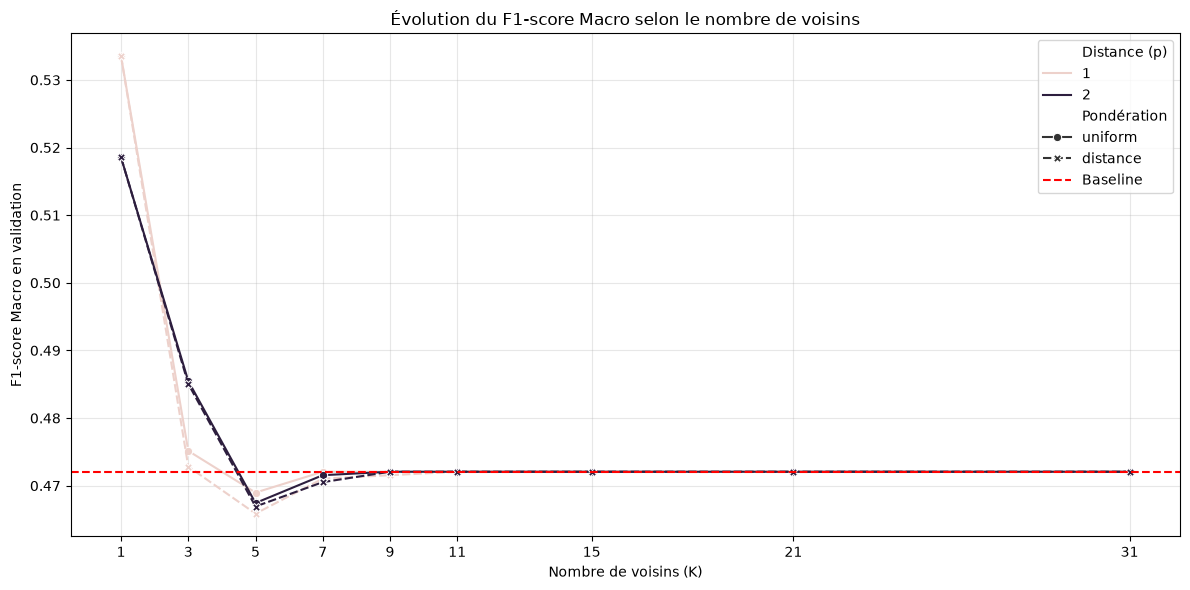

In [33]:
# Création de la figure
plt.figure(figsize=(12, 6))

# Visualisation des performances selon les hyperparamètres
sns.lineplot(
    data=resultats_optimisation,
    x='K',
    y='F1 Macro Validation',
    hue='Distance (p)',
    style='Pondération',
    markers=True,
    dashes=True,
    errorbar=None
)

# Score du modèle de référence
plt.axhline(
    y=scores_baseline['test_f1_macro'].mean(),
    color='red',
    linestyle='--',
    label='Baseline'
)

# Personnalisation du graphique
plt.title("Évolution du F1-score Macro selon le nombre de voisins")
plt.xlabel("Nombre de voisins (K)")
plt.ylabel("F1-score Macro en validation")
plt.xticks(param_grid['knn__n_neighbors'])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interprétation :**

Le graphique montre que les meilleures performances
sont obtenues avec K = 1 et la distance de Manhattan.

Lorsque le nombre de voisins augmente, le F1-score Macro
diminue puis se stabilise au niveau du modèle de référence
à partir de K = 9.

Ce comportement peut s'expliquer par le déséquilibre
des classes, qui favorise la classe majoritaire lorsque
le nombre de voisins augmente.

La configuration K = 1 reste la plus performante en
validation croisée parmi les configurations testées,
malgré son risque de surapprentissage.

### 8.5 Comparaison entre la Baseline, le KNN initial et le KNN optimisé

Les performances des trois modèles sont comparées
sur les mêmes plis de validation croisée afin de mesurer
l'apport de l'optimisation des hyperparamètres.

In [34]:
# Récupération du meilleur modèle KNN
knn_optimise = grid_search.best_estimator_

# Récupération de l'index de la meilleure configuration
meilleur_index = grid_search.best_index_

# Comparaison des performances des trois modèles
comparaison_finale_cv = pd.DataFrame({
    'Métrique': list(scoring.keys()),

    'Baseline': [
        scores_baseline['test_' + metrique].mean()
        for metrique in scoring
    ],

    'KNN initial (K=5)': [
        scores_knn['test_' + metrique].mean()
        for metrique in scoring
    ],

    'KNN optimisé (K=1)': [
        grid_search.cv_results_['mean_test_' + metrique][meilleur_index]
        for metrique in scoring
    ]
})

# Affichage du tableau comparatif
display(comparaison_finale_cv.round(4))

,Métrique,Baseline,KNN initial (K=5),KNN optimisé (K=1)
0,accuracy,0.8942,0.8778,0.8247
1,balanced_accuracy,0.5000,0.4908,0.5351
2,precision_macro,0.4471,0.4462,0.5359
3,recall_macro,0.5000,0.4908,0.5351
4,f1_macro,0.4721,0.4674,0.5335
5,roc_auc,0.5000,0.5556,0.5351


**Interprétation :**

L'optimisation du KNN améliore le F1-score Macro,
qui passe de 46,74 % à 53,35 %, dépassant ainsi
le modèle de référence (47,21 %).

La Balanced Accuracy et la Precision Macro progressent
également, malgré une diminution de l'accuracy globale.

Ces résultats suggèrent une meilleure prise en compte
des deux classes.

Cependant, les performances restent limitées et le
ROC-AUC de 53,51 % révèle une faible capacité de
discrimination.

Le risque de surapprentissage associé à K = 1 et
le déséquilibre des classes nécessitent des analyses
complémentaires avant la sélection définitive du modèle.

### 9. Analyse et sélection définitive du modèle

### 9.1 Comparaison du KNN avec et sans `jour_semaine`

Afin de vérifier l'intérêt prédictif du jour de la semaine,
deux configurations du KNN sont comparées avec et sans
cette variable.

Les deux configurations utilisent la même grille
d'hyperparamètres, les mêmes plis de validation croisée
et les mêmes métriques d'évaluation.

In [35]:
# Sélection des variables catégorielles sans jour_semaine
variables_cat_sans_jour = [
    variable for variable in variables_categorielles
    if variable != 'jour_semaine'
]

# Construction du prétraitement sans jour_semaine
preprocessor_sans_jour = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), variables_numeriques),
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), variables_cat_sans_jour),
        ('bool', 'passthrough', variables_booleennes)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

# Construction du pipeline KNN sans jour_semaine
pipeline_sans_jour = Pipeline(steps=[
    ('preprocessing', preprocessor_sans_jour),
    ('knn', KNeighborsClassifier())
])

# Affichage des variables catégorielles retenues
print("Variables catégorielles :", variables_cat_sans_jour)

display(pipeline_sans_jour)

Variables catégorielles : ['zone', 'genre', 'capacite']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_

In [36]:
# Configuration de GridSearchCV sans jour_semaine
grid_search_sans_jour = GridSearchCV(
    estimator=pipeline_sans_jour,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit='f1_macro',
    n_jobs=-1,
    return_train_score=True
)

# Recherche des meilleurs hyperparamètres
grid_search_sans_jour.fit(X_train, y_train)

# Affichage des résultats
print("Meilleurs hyperparamètres sans jour_semaine :")
display(grid_search_sans_jour.best_params_)

print("Meilleur F1-score Macro sans jour_semaine :",
      round(grid_search_sans_jour.best_score_, 4))

Meilleurs hyperparamètres sans jour_semaine :


{'knn__n_neighbors': 1, 'knn__p': 1, 'knn__weights': 'uniform'}

Meilleur F1-score Macro sans jour_semaine : 0.4876


### 9.1.1 Comparaison des performances avec et sans `jour_semaine`

In [37]:
# Récupération des index des meilleures configurations
index_avec_jour = grid_search.best_index_
index_sans_jour = grid_search_sans_jour.best_index_

# Comparaison des performances
comparaison_jour = pd.DataFrame({
    'Métrique': list(scoring.keys()),

    'Avec jour_semaine': [
        grid_search.cv_results_['mean_test_' + metrique][index_avec_jour]
        for metrique in scoring
    ],

    'Sans jour_semaine': [
        grid_search_sans_jour.cv_results_['mean_test_' + metrique][index_sans_jour]
        for metrique in scoring
    ]
})

# Calcul du gain apporté par la variable
comparaison_jour['Différence'] = (
    comparaison_jour['Avec jour_semaine']
    - comparaison_jour['Sans jour_semaine']
)

# Affichage des résultats
display(comparaison_jour.round(4))

# Comparaison de la stabilité des deux configurations
print("Écart-type F1 Macro avec jour_semaine :",
      round(grid_search.cv_results_['std_test_f1_macro'][index_avec_jour], 4))

print("Écart-type F1 Macro sans jour_semaine :",
      round(grid_search_sans_jour.cv_results_['std_test_f1_macro'][index_sans_jour], 4))

,Métrique,Avec jour_semaine,Sans jour_semaine,Différence
0,accuracy,0.8247,0.8211,0.0036
1,balanced_accuracy,0.5351,0.4892,0.0459
2,precision_macro,0.5359,0.4890,0.0469
3,recall_macro,0.5351,0.4892,0.0459
4,f1_macro,0.5335,0.4876,0.0459
5,roc_auc,0.5351,0.4892,0.0459


Écart-type F1 Macro avec jour_semaine : 0.0717
Écart-type F1 Macro sans jour_semaine : 0.0206


### 9.1.2 Visualisation et interprétation des résultats

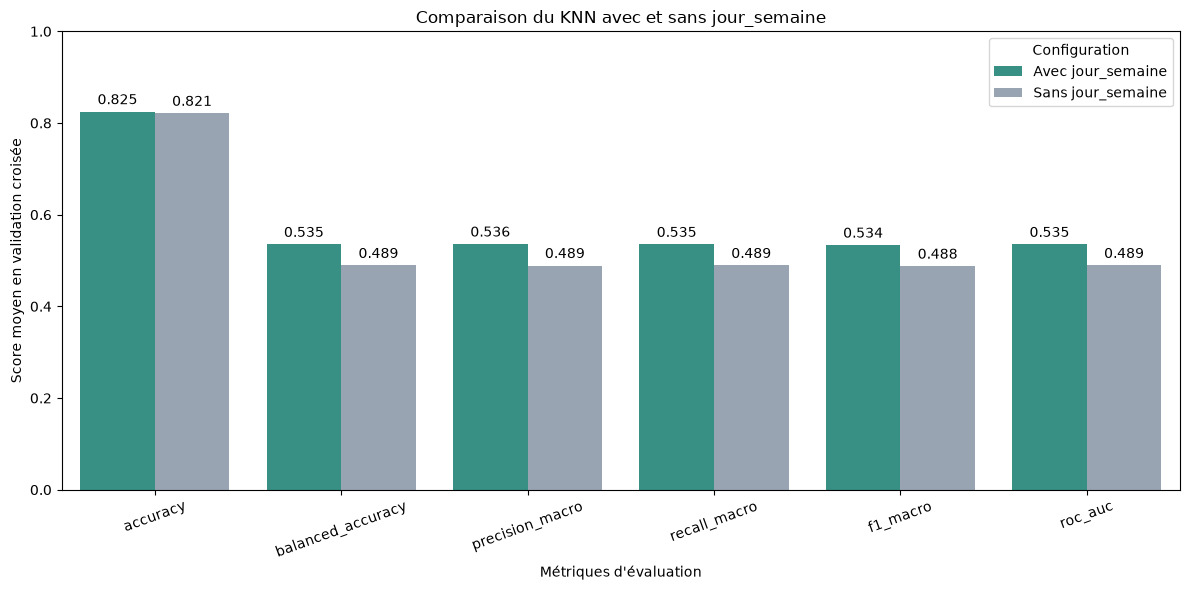

In [38]:
# Préparation des données pour la visualisation
comparaison_jour_graph = comparaison_jour.melt(
    id_vars='Métrique',
    value_vars=[
        'Avec jour_semaine',
        'Sans jour_semaine'
    ],
    var_name='Configuration',
    value_name='Score'
)

# Création de la figure
plt.figure(figsize=(12, 6))

# Comparaison graphique des performances
ax = sns.barplot(
    data=comparaison_jour_graph,
    x='Métrique',
    y='Score',
    hue='Configuration',
    palette=['#2A9D8F', '#94A3B8']
)

# Affichage des scores sur les barres
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)

# Personnalisation du graphique
plt.title("Comparaison du KNN avec et sans jour_semaine")
plt.xlabel("Métriques d'évaluation")
plt.ylabel("Score moyen en validation croisée")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Configuration")
plt.tight_layout()
plt.show()

**Interprétation :**

La conservation de la variable `jour_semaine`
améliore le F1-score Macro en validation croisée,
qui passe de 48,76 % à 53,35 %.

Cependant, l'écart-type augmente de 2,06 à 7,17
points de pourcentage, traduisant une plus grande
variabilité des performances.

La variable est conservée à ce stade, mais son
apport prédictif robuste n'est pas démontré.

Une validation croisée groupée par événement
permettra de compléter cette analyse.

### 9.2 Étude du déséquilibre des classes

Le déséquilibre de la variable cible peut favoriser
la prédiction de la classe majoritaire.

Une analyse des performances par classe est réalisée
afin d'identifier les difficultés du modèle à reconnaître
les consommateurs et les non-consommateurs.

### 9.2.1 Analyse des performances par classe

In [39]:
# Importation des bibliothèques
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

# Prédictions par validation croisée
y_pred_cv = cross_val_predict(
    knn_optimise,
    X_train,
    y_train,
    cv=cv
)

# Rapport de classification
rapport_cv = classification_report(
    y_train,
    y_pred_cv,
    labels=[0, 1],
    target_names=['Non-consommateurs', 'Consommateurs'],
    output_dict=True,
    zero_division=0
)

# Conversion du rapport en DataFrame
rapport_cv = pd.DataFrame(rapport_cv).T

# Affichage des résultats
display(rapport_cv.round(4))

,precision,recall,f1-score,support
Non-consommateurs,0.1724,0.1724,0.1724,58.0000
Consommateurs,0.9020,0.9020,0.9020,490.0000
accuracy,0.8248,0.8248,0.8248,0.8248
macro avg,0.5372,0.5372,0.5372,548.0000
weighted avg,0.8248,0.8248,0.8248,548.0000


**Interprétation :**

Le modèle KNN optimisé identifie correctement 90,20 %
des consommateurs, mais seulement 17,24 % des
non-consommateurs.

Cette différence révèle une difficulté importante à
reconnaître la classe minoritaire.

Sur les 58 non-consommateurs, seuls 10 sont correctement
identifiés, tandis que 48 sont classés comme consommateurs.

Ces résultats justifient l'étude d'un ajustement du seuil
de décision afin d'améliorer la détection de la classe
minoritaire.

### 9.2.2 Ajustement du seuil de décision

L'ajustement du seuil de décision permet de modifier
la classification à partir des probabilités estimées
par le KNN.

Une configuration avec plusieurs voisins est étudiée
afin d'améliorer la reconnaissance de la classe
minoritaire sans utiliser le jeu de test.

In [40]:
# Importation des bibliothèques
from sklearn.base import clone
from sklearn.metrics import f1_score, balanced_accuracy_score, recall_score

# Création d'un modèle KNN pour étudier le seuil
knn_seuil = clone(knn_optimise)

# Modification du nombre de voisins
knn_seuil.set_params(
    knn__n_neighbors=5
)

# Estimation des probabilités par validation croisée
probabilites_cv = cross_val_predict(
    knn_seuil,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

# Aperçu des probabilités de consommation
print("Probabilités de consommation :")
print(probabilites_cv[:10])

Probabilités de consommation :
[1.  0.6 1.  0.8 1.  1.  1.  1.  1.  1. ]


### 9.2.3 Comparaison des seuils de décision

Plusieurs seuils de décision sont évalués à partir des
probabilités obtenues par validation croisée.

L'objectif est d'améliorer la détection des non-consommateurs
tout en conservant un compromis satisfaisant entre les
performances des deux classes.

In [41]:
# Définition des seuils à tester
seuils = [0.1, 0.3, 0.5, 0.7, 0.9]

# Liste de stockage des résultats
resultats_seuils = []

# Évaluation de chaque seuil
for seuil in seuils:

    # Conversion des probabilités en classes
    y_pred_seuil = (probabilites_cv >= seuil).astype(int)

    # Calcul des métriques
    resultats_seuils.append({
        'Seuil': seuil,
        'Accuracy': (y_train == y_pred_seuil).mean(),
        'Balanced Accuracy': balanced_accuracy_score(
            y_train, y_pred_seuil
        ),
        'F1 Macro': f1_score(
            y_train, y_pred_seuil, average='macro'
        ),
        'Rappel non-consommateurs': recall_score(
            y_train, y_pred_seuil, pos_label=0
        ),
        'Rappel consommateurs': recall_score(
            y_train, y_pred_seuil, pos_label=1
        )
    })

# Conversion des résultats en DataFrame
resultats_seuils = pd.DataFrame(resultats_seuils)

# Affichage des résultats
display(resultats_seuils.round(4))

,Seuil,Accuracy,Balanced Accuracy,F1 Macro,Rappel non-consommateurs,Rappel consommateurs
0,0.1,0.8942,0.5000,0.4721,0.0000,1.0000
1,0.3,0.8942,0.5000,0.4721,0.0000,1.0000
2,0.5,0.8832,0.4939,0.4690,0.0000,0.9878
3,0.7,0.8157,0.4941,0.4938,0.0862,0.9020
4,0.9,0.6186,0.6043,0.4951,0.5862,0.6224


**Interprétation :**

L'augmentation du seuil de décision améliore la détection
de la classe minoritaire.

Avec un seuil de 0,9, le rappel des non-consommateurs
atteint 58,62 % et la Balanced Accuracy atteint 60,43 %.

Cependant, cette amélioration s'accompagne d'une diminution
de l'accuracy globale et du rappel des consommateurs.

Le F1-score Macro reste inférieur à celui du KNN optimisé
avec K = 1. Il est donc nécessaire d'étudier conjointement
le nombre de voisins et le seuil de décision afin de
rechercher un meilleur compromis.

### 9.2.4 Optimisation conjointe du nombre de voisins et du seuil

Plusieurs valeurs de K sont combinées à différents seuils
de décision afin de rechercher un meilleur compromis entre
la reconnaissance des consommateurs et des non-consommateurs.

Cette recherche est réalisée exclusivement à partir des
prédictions hors pli des données d'entraînement.

In [42]:
# Valeurs de K à tester
valeurs_k = param_grid['knn__n_neighbors']

# Seuils de décision à tester
seuils = [0.1, 0.3, 0.5, 0.7, 0.9]

# Stockage des résultats
resultats_k_seuil = []

# Évaluation des différentes valeurs de K
for k in valeurs_k:

    # Création d'une copie du modèle
    modele = clone(knn_optimise)

    # Modification des hyperparamètres
    modele.set_params(
        knn__n_neighbors=k,
        knn__p=1,
        knn__weights='uniform'
    )

    # Probabilités obtenues par validation croisée
    proba_cv = cross_val_predict(
        modele,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba'
    )[:, 1]

    # Évaluation des différents seuils
    for seuil in seuils:

        y_pred = (proba_cv >= seuil).astype(int)

        resultats_k_seuil.append({
            'K': k,
            'Seuil': seuil,
            'Accuracy': (y_train == y_pred).mean(),
            'Balanced Accuracy': balanced_accuracy_score(
                y_train, y_pred
            ),
            'F1 Macro': f1_score(
                y_train, y_pred, average='macro'
            ),
            'Rappel non-consommateurs': recall_score(
                y_train, y_pred, pos_label=0
            ),
            'Rappel consommateurs': recall_score(
                y_train, y_pred, pos_label=1
            )
        })

# Conversion en DataFrame
resultats_k_seuil = pd.DataFrame(resultats_k_seuil)

# Classement selon le F1-score Macro
resultats_k_seuil = resultats_k_seuil.sort_values(
    'F1 Macro',
    ascending=False
)

# Affichage des 10 meilleures configurations
display(resultats_k_seuil.head(10).round(4))

,K,Seuil,Accuracy,Balanced Accuracy,F1 Macro,Rappel non-consommateurs,Rappel consommateurs
0,1,0.1,0.8248,0.5372,0.5372,0.1724,0.9020
1,1,0.3,0.8248,0.5372,0.5372,0.1724,0.9020
2,1,0.5,0.8248,0.5372,0.5372,0.1724,0.9020
3,1,0.7,0.8248,0.5372,0.5372,0.1724,0.9020
4,1,0.9,0.8248,0.5372,0.5372,0.1724,0.9020
18,7,0.7,0.8796,0.5146,0.5094,0.0517,0.9776
8,3,0.7,0.6989,0.5504,0.5086,0.3621,0.7388
9,3,0.9,0.6989,0.5504,0.5086,0.3621,0.7388
23,9,0.7,0.8467,0.5039,0.5016,0.0690,0.9388
44,31,0.9,0.6442,0.5730,0.4962,0.4828,0.6633


**Interprétation :**

L'optimisation conjointe du nombre de voisins et du seuil
de décision confirme que K = 1 obtient le meilleur
F1-score Macro (53,72 %).

Les configurations utilisant plusieurs voisins et des
seuils plus élevés permettent toutefois d'améliorer
le rappel des non-consommateurs, au détriment de
l'accuracy globale.

Aucun seuil testé ne permet de dépasser le F1-score
Macro obtenu avec K = 1.

La sélection définitive du modèle nécessite donc une
analyse complémentaire de sa capacité de généralisation
à de nouveaux événements.

### 9.3 Vérification de la généralisation par événement

Une validation croisée groupée par événement est réalisée
afin d'évaluer la capacité du modèle à généraliser
ses prédictions à des événements non rencontrés pendant
l'apprentissage.

Cette méthode empêche les billets d'un même événement
d'apparaître simultanément dans les ensembles
d'apprentissage et de validation.

### 9.3.1 Configuration de la validation croisée groupée

In [43]:
# Importation de StratifiedGroupKFold
from sklearn.model_selection import StratifiedGroupKFold

# Récupération des événements associés aux billets d'entraînement
groupes_train = donnees_q5.loc[
    X_train.index, 'evenement_id'
]

# Configuration de la validation croisée groupée
cv_groupes = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Vérification des groupes
print("Nombre de billets d'entraînement :", len(groupes_train))
print("Nombre d'événements distincts :", groupes_train.nunique())

# Aperçu des événements
display(groupes_train.head(10))

Nombre de billets d'entraînement : 548
Nombre d'événements distincts : 94


162    EV315
231    EV376
338    EV341
437    EV387
412    EV300
106    EV318
327    EV330
549    EV340
683    EV342
576    EV303
Name: evenement_id, dtype: str

### 9.3.2 Vérification de la séparation des événements

In [44]:
# Stockage des résultats de vérification
verification_groupes = []

# Parcours des cinq plis de validation croisée
for pli, (train_idx, val_idx) in enumerate(
    cv_groupes.split(X_train, y_train, groups=groupes_train),
    start=1
):

    # Événements présents dans chaque ensemble
    evenements_train = set(groupes_train.iloc[train_idx])
    evenements_val = set(groupes_train.iloc[val_idx])

    # Recherche des événements communs
    evenements_communs = evenements_train.intersection(
        evenements_val
    )

    # Stockage des résultats
    verification_groupes.append({
        'Pli': pli,
        'Billets Train': len(train_idx),
        'Billets Validation': len(val_idx),
        'Événements Train': len(evenements_train),
        'Événements Validation': len(evenements_val),
        'Événements communs': len(evenements_communs)
    })

# Conversion en DataFrame
verification_groupes = pd.DataFrame(verification_groupes)

# Affichage des résultats
display(verification_groupes)

,Pli,Billets Train,Billets Validation,Événements Train,Événements Validation,Événements communs
0,1,437,111,75,19,0
1,2,439,109,76,18,0
2,3,441,107,76,18,0
3,4,437,111,75,19,0
4,5,438,110,74,20,0


**Interprétation :**

La validation croisée groupée répartit les 94 événements
en cinq plis sans chevauchement entre les ensembles
d'apprentissage et de validation.

L'absence d'événements communs permet d'évaluer la
capacité du modèle à généraliser ses prédictions
à des événements non rencontrés lors de l'apprentissage.

### 9.3.3 Comparaison des performances en validation groupée

Les configurations sélectionnées précédemment sont
évaluées par validation croisée groupée afin d'étudier
leur capacité de généralisation à de nouveaux événements.

Les performances sont comparées selon le F1-score Macro,
la Balanced Accuracy, le ROC-AUC et le rappel de chaque
classe.

In [45]:
# Importation des métriques complémentaires
from sklearn.metrics import accuracy_score, roc_auc_score

# Définition des configurations à comparer
configurations_groupes = [
    ('Baseline', clone(baseline), 0.5),

    ('KNN K=1 avec jour', clone(knn_optimise), 0.5),

    ('KNN K=1 sans jour',
     clone(grid_search_sans_jour.best_estimator_), 0.5),

    ('KNN K=3', clone(knn_optimise).set_params(
        knn__n_neighbors=3), 0.7),

    ('KNN K=5', clone(knn_optimise).set_params(
        knn__n_neighbors=5), 0.9),

    ('KNN K=7', clone(knn_optimise).set_params(
        knn__n_neighbors=7), 0.7),

    ('KNN K=31', clone(knn_optimise).set_params(
        knn__n_neighbors=31), 0.9)
]

# Stockage des résultats
resultats_groupes = []

# Évaluation des différentes configurations
for nom, modele, seuil in configurations_groupes:

    # Probabilités obtenues par validation croisée groupée
    proba_groupes = cross_val_predict(
        modele,
        X_train,
        y_train,
        cv=cv_groupes,
        groups=groupes_train,
        method='predict_proba'
    )[:, 1]

    # Application du seuil de décision
    y_pred_groupes = (proba_groupes >= seuil).astype(int)

    # Calcul des métriques
    resultats_groupes.append({
        'Modèle': nom,
        'Seuil': seuil,
        'Accuracy': accuracy_score(y_train, y_pred_groupes),
        'Balanced Accuracy': balanced_accuracy_score(
            y_train, y_pred_groupes
        ),
        'F1 Macro': f1_score(
            y_train, y_pred_groupes, average='macro'
        ),
        'ROC-AUC': roc_auc_score(y_train, proba_groupes),
        'Rappel non-consommateurs': recall_score(
            y_train, y_pred_groupes, pos_label=0
        ),
        'Rappel consommateurs': recall_score(
            y_train, y_pred_groupes, pos_label=1
        )
    })

# Conversion en DataFrame
resultats_groupes = pd.DataFrame(resultats_groupes)

# Classement selon le F1-score Macro
resultats_groupes = resultats_groupes.sort_values(
    'F1 Macro', ascending=False
)

# Affichage des résultats
display(resultats_groupes.round(4))

,Modèle,Seuil,Accuracy,Balanced Accuracy,F1 Macro,ROC-AUC,Rappel non-consommateurs,Rappel consommateurs
1,KNN K=1 avec jour,0.5,0.8558,0.5546,0.5614,0.5546,0.1724,0.9367
2,KNN K=1 sans jour,0.5,0.8321,0.5489,0.5496,0.5489,0.1897,0.9082
3,KNN K=3,0.7,0.7245,0.5495,0.5173,0.5481,0.3276,0.7714
5,KNN K=7,0.7,0.8704,0.5019,0.4919,0.5747,0.0345,0.9694
4,KNN K=5,0.9,0.6113,0.5622,0.4779,0.5582,0.5000,0.6245
0,Baseline,0.5,0.8942,0.5000,0.4721,0.5000,0.0000,1.0000
6,KNN K=31,0.9,0.6369,0.5081,0.4676,0.5471,0.3448,0.6714


**Interprétation :**

Le KNN avec K = 1 et la variable `jour_semaine`
obtient le meilleur F1-score Macro (56,14 %)
parmi les configurations évaluées.

Sans cette variable, le score atteint 54,96 %,
soit une différence limitée de 1,18 point.

La variable `jour_semaine` est conservée dans
le modèle sélectionné, mais son apport prédictif
robuste reste à démontrer.

Le faible rappel des non-consommateurs (17,24 %)
et le ROC-AUC de 0,5546 révèlent une capacité
de discrimination limitée.

Cette validation groupée reste une analyse de
sélection réalisée sur les données d'entraînement
et ne constitue pas une évaluation indépendante.

### 9.4 Sélection définitive du modèle

À l'issue des différentes expérimentations, le modèle
KNN avec K = 1, une distance de Manhattan, une pondération
uniforme et un seuil de décision de 0,5 est retenu.

Cette configuration obtient le meilleur F1-score Macro
parmi les modèles évalués en validation croisée classique
et groupée.

Les dix variables prédictives sont conservées.

Le modèle final est entraîné sur l'ensemble des données
d'entraînement avant son évaluation sur le jeu de test.

In [46]:
# Création du modèle final à partir du KNN optimisé
modele_final = clone(knn_optimise)

# Définition du seuil de décision final
seuil_final = 0.5

# Entraînement sur l'ensemble des données d'entraînement
modele_final.fit(X_train, y_train)

# Affichage de la configuration finale
print("Hyperparamètres du modèle final :")
display(modele_final.named_steps['knn'].get_params())

print("Seuil de décision :", seuil_final)

print("Nombre de variables prédictives :", X_train.shape[1])

print("Nombre de billets d'entraînement :", len(X_train))

print("Entraînement du modèle final terminé.")

# Affichage du pipeline final
display(modele_final)

Hyperparamètres du modèle final :


{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 1,
 'p': 1,
 'weights': 'uniform'}

Seuil de décision : 0.5
Nombre de variables prédictives : 10
Nombre de billets d'entraînement : 548
Entraînement du modèle final terminé.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['prix_paye_eur','achat_jours_avant','age',...,'capacite','deja_venu', 'invitation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equival

**Limite du modèle sélectionné :**

Avec K = 1, les probabilités estimées sont limitées
aux valeurs 0 et 1.

Cette caractéristique réduit la capacité du modèle à
classer finement les spectateurs selon leur propension
à consommer au bar.

Une configuration adaptée au classement pourra être
étudiée dans le cadre de la question 6.

### 10. Évaluation finale sur le jeu de test

Le modèle final est évalué sur les 138 billets réservés
au test, sans modification supplémentaire de ses
hyperparamètres ni de son seuil de décision.

### 10.1 Prédictions sur le jeu de test

In [47]:
# Estimation des probabilités de consommation
y_proba_test = modele_final.predict_proba(X_test)[:, 1]

# Prédiction des classes selon le seuil final
y_pred_test = (y_proba_test >= seuil_final).astype(int)

# Comparaison des valeurs réelles et prédites
predictions_test = pd.DataFrame({
    'Classe réelle': y_test,
    'Probabilité de consommation': y_proba_test,
    'Classe prédite': y_pred_test
}, index=X_test.index)

# Vérification du nombre de prédictions
print("Nombre de prédictions :", len(y_pred_test))

# Aperçu des résultats
display(predictions_test.head(10))

Nombre de prédictions : 138


,Classe réelle,Probabilité de consommation,Classe prédite
173,1,1.0,1
584,1,0.0,0
128,0,1.0,1
679,1,0.0,0
588,1,0.0,0
543,1,1.0,1
429,1,1.0,1
471,1,1.0,1
568,1,0.0,0
254,1,1.0,1


### 10.2 Calcul des métriques finales

Les performances du modèle final sont mesurées à l'aide
de plusieurs métriques afin de tenir compte du déséquilibre
des classes et d'évaluer sa capacité de généralisation.

In [48]:
# Importation des métriques d'évaluation
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calcul des métriques finales
resultats_test = pd.DataFrame({
    'Métrique': [
        'Accuracy',
        'Balanced Accuracy',
        'Precision Macro',
        'Recall Macro',
        'F1 Macro',
        'ROC-AUC'
    ],
    'Score': [
        accuracy_score(y_test, y_pred_test),
        balanced_accuracy_score(y_test, y_pred_test),
        precision_score(
            y_test, y_pred_test,
            average='macro', zero_division=0
        ),
        recall_score(
            y_test, y_pred_test,
            average='macro', zero_division=0
        ),
        f1_score(
            y_test, y_pred_test,
            average='macro', zero_division=0
        ),
        roc_auc_score(y_test, y_proba_test)
    ]
})

# Conversion des scores en pourcentages
resultats_test['Score (%)'] = resultats_test['Score'] * 100

# Affichage des résultats
display(resultats_test.round(4))

,Métrique,Score,Score (%)
0,Accuracy,0.7681,76.8116
1,Balanced Accuracy,0.4591,45.9101
2,Precision Macro,0.4699,46.9915
3,Recall Macro,0.4591,45.9101
4,F1 Macro,0.4633,46.3296
5,ROC-AUC,0.4591,45.9101


**Interprétation :**

Le modèle final obtient une accuracy de 76,81 % et
un F1-score Macro de 46,33 % sur le jeu de test.

La Balanced Accuracy et le ROC-AUC de 45,91 %
indiquent une faible capacité à distinguer les
consommateurs des non-consommateurs.

La diminution des performances par rapport à la
validation croisée groupée suggère des difficultés
de généralisation.

Ces résultats sont cohérents avec le risque de
surapprentissage identifié précédemment pour K = 1.

### 10.3 Matrice de confusion

La matrice de confusion permet d'analyser les prédictions
correctes et les erreurs de classification du modèle
pour chacune des deux classes.

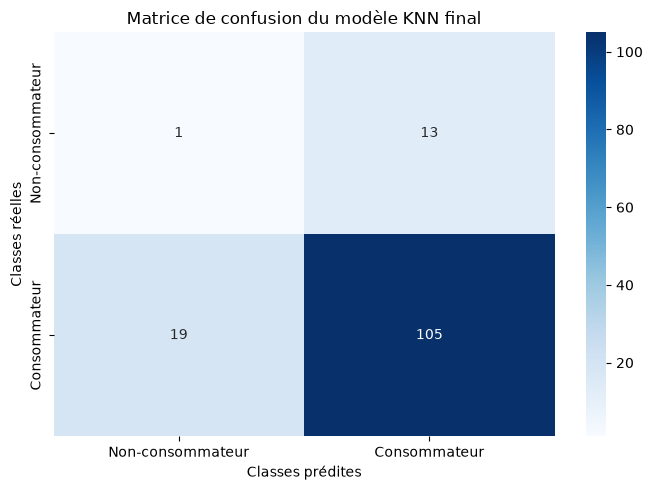

In [49]:
# Importation de la matrice de confusion
from sklearn.metrics import confusion_matrix

# Calcul de la matrice de confusion
matrice_confusion = confusion_matrix(
    y_test,
    y_pred_test,
    labels=[0, 1]
)

# Création de la figure
plt.figure(figsize=(7, 5))

# Visualisation de la matrice de confusion
sns.heatmap(
    matrice_confusion,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-consommateur', 'Consommateur'],
    yticklabels=['Non-consommateur', 'Consommateur']
)

# Personnalisation du graphique
plt.title("Matrice de confusion du modèle KNN final")
plt.xlabel("Classes prédites")
plt.ylabel("Classes réelles")
plt.tight_layout()
plt.show()

**Interprétation :**

Sur les 138 billets de test, le modèle réalise
106 prédictions correctes et 32 erreurs de classification.

Il identifie correctement 105 consommateurs sur 124
(84,68 %), mais seulement 1 non-consommateur sur 14
(7,14 %).

Ces résultats confirment les difficultés du modèle
à reconnaître la classe minoritaire.

Les erreurs de classification limitent la pertinence
du modèle pour une stratégie de ciblage commercial.

### 10.4 Rapport de classification

Le rapport de classification permet d'évaluer séparément
les performances du modèle sur les consommateurs et
les non-consommateurs.

In [50]:
# Importation du rapport de classification
from sklearn.metrics import classification_report

# Calcul du rapport de classification
rapport_test = classification_report(
    y_test,
    y_pred_test,
    labels=[0, 1],
    target_names=['Non-consommateurs', 'Consommateurs'],
    output_dict=True,
    zero_division=0
)

# Conversion du rapport en DataFrame
rapport_test = pd.DataFrame(rapport_test).T

# Affichage des résultats
display(rapport_test.round(4))

,precision,recall,f1-score,support
Non-consommateurs,0.0500,0.0714,0.0588,14.0000
Consommateurs,0.8898,0.8468,0.8678,124.0000
accuracy,0.7681,0.7681,0.7681,0.7681
macro avg,0.4699,0.4591,0.4633,138.0000
weighted avg,0.8046,0.7681,0.7857,138.0000


**Interprétation :**

Le rapport de classification révèle un déséquilibre
important des performances entre les deux classes.

Le F1-score des consommateurs atteint 86,78 %, contre
seulement 5,88 % pour les non-consommateurs.

La différence entre le F1-score Macro (46,33 %) et
le F1-score pondéré (78,57 %) montre que les performances
globales sont principalement influencées par la classe
majoritaire.

Ces résultats confirment les limites du modèle dans
la reconnaissance de la classe minoritaire.

### 10.5 Courbe ROC et AUC

La courbe ROC permet d'évaluer la capacité du modèle
à distinguer les consommateurs des non-consommateurs.

L'aire sous la courbe (AUC) mesure cette capacité
de discrimination indépendamment du seuil de décision.

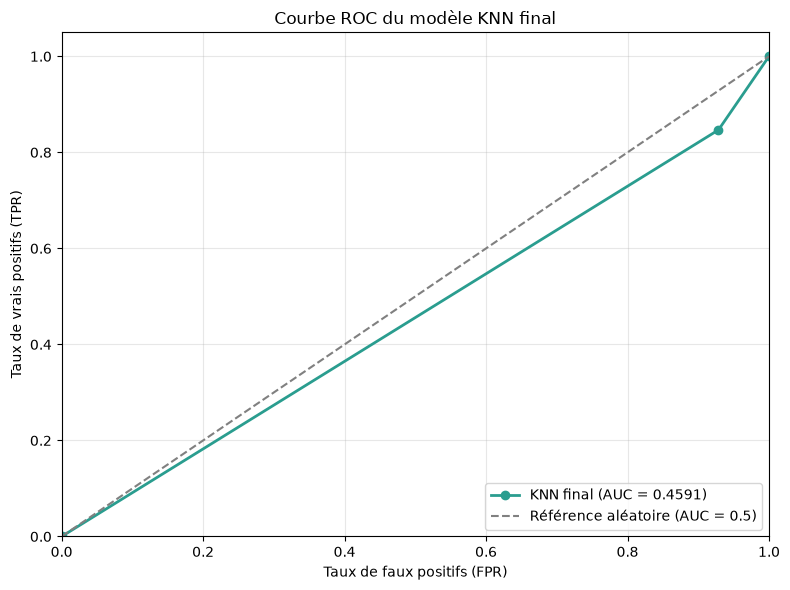

In [51]:
# Importation de la fonction roc_curve
from sklearn.metrics import roc_curve

# Calcul des points de la courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba_test)

# Calcul de l'aire sous la courbe
auc_test = roc_auc_score(y_test, y_proba_test)

# Création de la figure
plt.figure(figsize=(8, 6))

# Courbe ROC du modèle KNN
plt.plot(
    fpr,
    tpr,
    color='#2A9D8F',
    linewidth=2,
    marker='o',
    label=f'KNN final (AUC = {auc_test:.4f})'
)

# Ligne de référence aléatoire
plt.plot(
    [0, 1],
    [0, 1],
    color='gray',
    linestyle='--',
    label='Référence aléatoire (AUC = 0.5)'
)

# Personnalisation du graphique
plt.title("Courbe ROC du modèle KNN final")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interprétation :**

Le modèle KNN final obtient un ROC-AUC de 0,4591,
proche du niveau de référence aléatoire de 0,5.

Ce résultat ne permet pas de démontrer une capacité
de discrimination supérieure au hasard sur le
jeu de test.

La petite taille de la classe minoritaire, composée
de seulement 14 non-consommateurs, impose toutefois
de rester prudent dans cette interprétation.

L'utilisation de K = 1 limite les probabilités
estimées aux valeurs 0 et 1, ce qui réduit également
la capacité du modèle à classer les spectateurs.

### 10.6 Comparaison finale avec la baseline

Le modèle KNN final est comparé à un modèle de référence
prédisant systématiquement la classe majoritaire.

Cette comparaison permet de mesurer la valeur ajoutée
réelle du KNN sur le jeu de test.

In [52]:
# Entraînement du modèle de référence
baseline_finale = DummyClassifier(strategy='most_frequent')
baseline_finale.fit(X_train, y_train)

# Prédictions sur le jeu de test
y_pred_baseline = baseline_finale.predict(X_test)

# Probabilités estimées par la baseline
y_proba_baseline = baseline_finale.predict_proba(X_test)[:, 1]

# Comparaison des performances finales
comparaison_test = pd.DataFrame({
    'Métrique': resultats_test['Métrique'],

    'Baseline': [
        accuracy_score(y_test, y_pred_baseline),
        balanced_accuracy_score(y_test, y_pred_baseline),
        precision_score(
            y_test, y_pred_baseline,
            average='macro', zero_division=0
        ),
        recall_score(
            y_test, y_pred_baseline,
            average='macro', zero_division=0
        ),
        f1_score(
            y_test, y_pred_baseline,
            average='macro', zero_division=0
        ),
        roc_auc_score(y_test, y_proba_baseline)
    ],

    'KNN final': resultats_test['Score']
})

# Calcul de la différence de performance
comparaison_test['Différence'] = (
    comparaison_test['KNN final']
    - comparaison_test['Baseline']
)

# Affichage des résultats
display(comparaison_test.round(4))

,Métrique,Baseline,KNN final,Différence
0,Accuracy,0.8986,0.7681,-0.1304
1,Balanced Accuracy,0.5000,0.4591,-0.0409
2,Precision Macro,0.4493,0.4699,0.0206
3,Recall Macro,0.5000,0.4591,-0.0409
4,F1 Macro,0.4733,0.4633,-0.0100
5,ROC-AUC,0.5000,0.4591,-0.0409


**Interprétation :**

Le modèle KNN final présente des performances inférieures
au modèle de référence sur la majorité des métriques.

Malgré une légère amélioration de la Precision Macro,
son F1-score Macro (46,33 %) reste inférieur à celui
de la baseline (47,33 %).

Ces résultats montrent que le modèle KNN ne permet pas
d'apporter une valeur prédictive suffisante sur le jeu
de test.

### 11. Analyse complémentaire de la consommation par zone

Les performances prédictives du modèle KNN étant
insuffisantes, une analyse descriptive par zone est
réalisée afin d'identifier les différences de consommation
et d'orienter les décisions du partenaire restauration.

### 11.1 Statistiques descriptives par zone

In [53]:
# Analyse de la consommation au bar par zone
analyse_zone = donnees_q5.groupby('zone').agg(
    nombre_billets=('billet_id', 'count'),
    nombre_consommateurs=('conso_bar', 'sum'),
    taux_consommation=('conso_bar', 'mean'),
    consommation_moyenne=('conso_bar_eur', 'mean'),
    chiffre_affaires_bar=('conso_bar_eur', 'sum')
)

# Conversion du taux de consommation en pourcentage
analyse_zone['taux_consommation'] *= 100

# Calcul de la part du public par zone
analyse_zone['part_public'] = (
    analyse_zone['nombre_billets']
    / analyse_zone['nombre_billets'].sum()
) * 100

# Calcul de la part du chiffre d'affaires par zone
analyse_zone['part_ca_bar'] = (
    analyse_zone['chiffre_affaires_bar']
    / analyse_zone['chiffre_affaires_bar'].sum()
) * 100

# Affichage des résultats
display(analyse_zone.round(2))

,nombre_billets,nombre_consommateurs,taux_consommation,consommation_moyenne,chiffre_affaires_bar,part_public,part_ca_bar
zone,,,,,,,
fosse,193,177,91.71,5.89,1136.03,28.13,23.33
gradin bas,241,217,90.04,5.78,1393.29,35.13,28.62
gradin haut,207,175,84.54,5.16,1068.56,30.17,21.95
loge,45,45,100.00,28.23,1270.56,6.56,26.10


**Interprétation :**

L'analyse descriptive révèle des différences importantes
de consommation entre les zones de la salle.

La loge représente seulement 6,56 % du public étudié,
mais génère 26,10 % du chiffre d'affaires observé au bar,
avec une dépense moyenne de 28,23 € par spectateur.

Le gradin bas génère le chiffre d'affaires total le plus
élevé, tandis que le gradin haut présente le taux de
consommation le plus faible (84,54 %).

Ces observations suggèrent qu'une répartition différenciée
des ressources de restauration selon les zones pourrait
être plus pertinente qu'une prédiction individuelle
fondée sur le KNN étudié.

### 11.2 Test d'indépendance du khi-deux

Un test du khi-deux est réalisé afin d'étudier l'existence
d'une association statistique entre la zone du spectateur
et sa consommation au bar.

Le seuil de significativité retenu est de 5 %.

In [54]:
# Importation du test du khi-deux
from scipy.stats import chi2_contingency

# Construction du tableau de contingence
tableau_contingence = pd.crosstab(
    donnees_q5['zone'],
    donnees_q5['conso_bar']
)

# Affichage des effectifs observés
display(tableau_contingence)

# Application du test du khi-deux
chi2, p_value, ddl, effectifs_theoriques = chi2_contingency(
    tableau_contingence
)

# Affichage des résultats du test
print("Statistique du khi-deux :", round(chi2, 4))
print("P-value :", round(p_value, 6))
print("Degrés de liberté :", ddl)

# Vérification des effectifs théoriques
display(pd.DataFrame(
    effectifs_theoriques,
    index=tableau_contingence.index,
    columns=tableau_contingence.columns
).round(2))

# Décision statistique
if p_value < 0.05:
    print("Rejet de H0 : association statistiquement significative.")
else:
    print("H0 ne peut pas être rejetée.")

conso_bar,0,1
zone,,
fosse,16,177
gradin bas,24,217
gradin haut,32,175
loge,0,45


Statistique du khi-deux : 11.7785
P-value : 0.008182
Degrés de liberté : 3


conso_bar,0,1
zone,,
fosse,20.26,172.74
gradin bas,25.29,215.71
gradin haut,21.73,185.27
loge,4.72,40.28


Rejet de H0 : association statistiquement significative.


**Interprétation :**

Le test du khi-deux fournit une statistique de 11,7785
avec une p-value de 0,008182, inférieure au seuil de
significativité de 5 %.

L'hypothèse d'indépendance entre la zone et la
consommation au bar est donc rejetée.

Le gradin haut présente davantage de non-consommateurs
que prévu sous l'hypothèse d'indépendance, tandis que
la loge présente un taux de consommation particulièrement
élevé.

Ces résultats suggèrent que la zone constitue un facteur
pertinent pour l'analyse de la consommation au bar.

Toutefois, cette association ne démontre ni une relation
de causalité ni une capacité prédictive suffisante.

Le test reste exploratoire en raison de la possible
dépendance entre les billets d'un même événement.
La vérification des effectifs théoriques montre que
7 cellules sur 8 présentent un effectif supérieur
ou égal à 5. Aucun effectif théorique n'est inférieur à 1.

Les conditions usuelles relatives aux effectifs
sont donc globalement respectées, sous réserve
de l'hypothèse d'indépendance des observations.

### 11.3 Visualisation du chiffre d'affaires par zone

La comparaison entre la part du public et la part du
chiffre d'affaires du bar permet d'identifier les zones
présentant un potentiel commercial important.

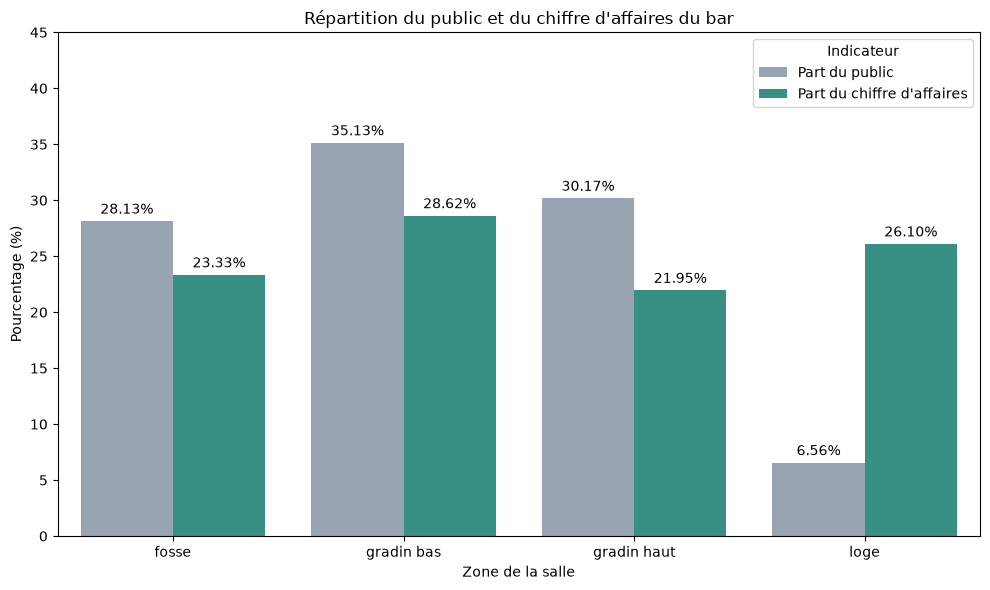

In [55]:
# Préparation des données pour la visualisation
analyse_zone_graph = analyse_zone.reset_index().melt(
    id_vars='zone',
    value_vars=['part_public', 'part_ca_bar'],
    var_name='Indicateur',
    value_name='Pourcentage'
)

# Renommage des indicateurs
analyse_zone_graph['Indicateur'] = (
    analyse_zone_graph['Indicateur'].replace({
        'part_public': 'Part du public',
        'part_ca_bar': "Part du chiffre d'affaires"
    })
)

# Création de la figure
plt.figure(figsize=(10, 6))

# Comparaison des deux indicateurs
ax = sns.barplot(
    data=analyse_zone_graph,
    x='zone',
    y='Pourcentage',
    hue='Indicateur',
    palette=['#94A3B8', '#2A9D8F']
)

# Affichage des pourcentages sur les barres
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

# Personnalisation du graphique
plt.title("Répartition du public et du chiffre d'affaires du bar")
plt.xlabel("Zone de la salle")
plt.ylabel("Pourcentage (%)")
plt.ylim(0, 45)
plt.legend(title="Indicateur")
plt.tight_layout()
plt.show()

**Interprétation :**

La comparaison entre la répartition du public et celle
du chiffre d'affaires du bar met en évidence une forte
contribution commerciale de la loge.

Cette zone représente seulement 6,56 % des spectateurs
étudiés, mais génère 26,10 % du chiffre d'affaires
observé au bar.

À l'inverse, le gradin haut représente 30,17 % du public
pour seulement 21,95 % du chiffre d'affaires.

Ces résultats justifient d'envisager une répartition
différenciée des ressources de restauration, avec une
attention particulière portée à la loge.

Toutefois, ces proportions concernent l'échantillon
étudié et ne correspondent pas nécessairement à la
répartition réelle des ventes sur toute la saison.

### 11.4 Modèle KNN avec la zone seule

L'objectif est d'évaluer le pouvoir prédictif de la variable
`zone` indépendamment des autres variables.

Ce modèle simplifié est comparé au KNN utilisant les dix
variables prédictives afin d'étudier si une approche moins
complexe offre une meilleure capacité de discrimination.

### 11.4.1 Construction du modèle

In [56]:
# Sélection de la variable zone
X_train_zone = X_train[['zone']].copy()

# Construction du pipeline KNN avec la zone seule
pipeline_zone = Pipeline(steps=[
    ('encodage', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    )),
    ('knn', KNeighborsClassifier(
        metric='manhattan',
        weights='uniform'
    ))
])

# Vérification des dimensions
print("Dimensions de X_train_zone :", X_train_zone.shape)

# Affichage du pipeline
display(pipeline_zone)

Dimensions de X_train_zone : (548, 1)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encodage', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.

### 11.4.2 Recherche du meilleur K

Plusieurs valeurs de K sont évaluées par validation
croisée groupée à 5 plis.

Le ROC-AUC est retenu comme critère d'optimisation
afin d'évaluer la capacité discriminante de la variable
`zone` utilisée seule.

In [57]:
# Définition des valeurs de K à tester
param_grid_zone = {
    'knn__n_neighbors': [1, 3, 5, 11, 21, 31, 45, 61, 81, 101]
}

# Configuration de la recherche des hyperparamètres
grid_search_zone = GridSearchCV(
    estimator=pipeline_zone,
    param_grid=param_grid_zone,
    cv=cv_groupes,
    scoring='roc_auc',
    n_jobs=-1,
    return_train_score=True
)

# Recherche du meilleur nombre de voisins
grid_search_zone.fit(
    X_train_zone,
    y_train,
    groups=groupes_train
)

# Affichage des meilleurs résultats
print("Meilleurs hyperparamètres :")
display(grid_search_zone.best_params_)

print("Meilleur ROC-AUC :",
      round(grid_search_zone.best_score_, 4))

Meilleurs hyperparamètres :


{'knn__n_neighbors': 5}

Meilleur ROC-AUC : 0.5931


**Interprétation :**

La recherche du meilleur nombre de voisins identifie
K = 5 comme la configuration la plus performante parmi
les valeurs testées, avec un ROC-AUC moyen de 0,5931.

Ce résultat suggère que la variable `zone` possède
un certain pouvoir discriminant, bien que celui-ci
reste limité.

Une comparaison dans les mêmes conditions d'évaluation
est nécessaire pour déterminer l'intérêt de ce modèle
simplifié.

**Limite méthodologique :**

Les spectateurs appartenant à une même zone possèdent
les mêmes caractéristiques après encodage.

Le KNN peut donc rencontrer plusieurs voisins à distance
identique, dont la sélection peut dépendre de l'ordre
des observations.

Par ailleurs, le meilleur K est sélectionné sur les
mêmes plis que ceux utilisés pour la comparaison
des performances. Les résultats restent exploratoires.

### 11.4.3 Comparaison des performances des modèles

Les trois modèles sont évalués sur les mêmes plis
de validation croisée groupée et avec les mêmes
métriques afin de garantir une comparaison cohérente.
Les métriques présentées dans cette section correspondent
à la moyenne des scores obtenus sur les cinq plis.

Dans la section 9.3.3, elles étaient calculées sur
l'ensemble des prédictions hors pli.

Cette différence de méthode explique les légers écarts
entre les résultats des deux sections.

In [58]:
# Récupération du meilleur KNN utilisant la zone seule
knn_zone = grid_search_zone.best_estimator_

# Définition des modèles à comparer
modeles_comparaison_zone = [
    ('Baseline', clone(baseline), X_train),

    ('KNN 10 variables', clone(modele_final), X_train),

    ('KNN zone seule', clone(knn_zone), X_train_zone)
]

# Stockage des résultats
resultats_comparaison_zone = []

# Évaluation des trois modèles
for nom, modele, donnees in modeles_comparaison_zone:

    scores = cross_validate(
        modele,
        donnees,
        y_train,
        cv=cv_groupes,
        groups=groupes_train,
        scoring=scoring
    )

    # Calcul des scores moyens
    resultats_comparaison_zone.append({
        'Modèle': nom,
        'Accuracy': scores['test_accuracy'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'F1 Macro': scores['test_f1_macro'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean(),
        'Écart-type ROC-AUC': scores['test_roc_auc'].std()
    })

# Conversion en DataFrame
comparaison_zone = pd.DataFrame(
    resultats_comparaison_zone
)

# Affichage des résultats
display(comparaison_zone.round(4))

,Modèle,Accuracy,Balanced Accuracy,F1 Macro,ROC-AUC,Écart-type ROC-AUC
0,Baseline,0.8942,0.5000,0.4721,0.5000,0.0000
1,KNN 10 variables,0.8560,0.5557,0.5584,0.5557,0.0337
2,KNN zone seule,0.8942,0.5000,0.4721,0.5931,0.0786


**Interprétation :**

Le KNN utilisant uniquement la variable `zone` obtient
un ROC-AUC moyen de 0,5931, contre 0,5557 pour le KNN
utilisant les dix variables prédictives.

Ce résultat suggère que la zone contient une information
discriminante, malgré une capacité prédictive limitée.

Cependant, son F1-score Macro et sa Balanced Accuracy
restent identiques à ceux du modèle de référence.

La zone semble donc plus intéressante pour le classement
des spectateurs que pour leur classification individuelle.

Ces résultats restent exploratoires et ne permettent pas
d'affirmer que la zone est la seule variable prédictive utile.

### 11.4.4 Estimation directe des taux de consommation par zone

Une estimation directe des probabilités de consommation
par zone est étudiée comme référence complémentaire
au KNN simplifié.

Les taux sont calculés exclusivement sur les plis
d'apprentissage afin d'éviter les fuites de données
entre apprentissage et validation.

In [59]:
# Stockage des résultats
resultats_taux_zone = []

# Parcours des plis de validation croisée groupée
for train_idx, val_idx in cv_groupes.split(
    X_train, y_train, groups=groupes_train
):

    # Séparation des données du pli
    X_apprentissage = X_train.iloc[train_idx]
    y_apprentissage = y_train.iloc[train_idx]

    X_validation = X_train.iloc[val_idx]
    y_validation = y_train.iloc[val_idx]

    # Calcul des taux de consommation par zone
    taux_zone = y_apprentissage.groupby(
        X_apprentissage['zone']
    ).mean()

    # Attribution des probabilités selon la zone
    proba_zone = X_validation['zone'].map(taux_zone)

    # Gestion des éventuelles zones inconnues
    proba_zone = proba_zone.fillna(
        y_apprentissage.mean()
    )

    # Prédiction des classes
    pred_zone = (proba_zone >= 0.5).astype(int)

    # Calcul des métriques
    resultats_taux_zone.append({
        'Accuracy': accuracy_score(
            y_validation, pred_zone
        ),
        'Balanced Accuracy': balanced_accuracy_score(
            y_validation, pred_zone
        ),
        'F1 Macro': f1_score(
            y_validation, pred_zone, average='macro'
        ),
        'ROC-AUC': roc_auc_score(
            y_validation, proba_zone
        )
    })

# Conversion en DataFrame
resultats_taux_zone = pd.DataFrame(resultats_taux_zone)

# Calcul des performances moyennes
display(resultats_taux_zone.mean().round(4))

# Calcul de la variabilité du ROC-AUC
print("Écart-type ROC-AUC :",
      round(resultats_taux_zone['ROC-AUC'].std(ddof=0), 4))

Accuracy             0.8942
Balanced Accuracy    0.5000
F1 Macro             0.4721
ROC-AUC              0.6093
dtype: float64

Écart-type ROC-AUC : 0.0799


**Interprétation :**

L'estimation directe des taux de consommation par zone
obtient un ROC-AUC moyen de 0,6093, supérieur à celui
du KNN utilisant uniquement la zone (0,5931) et du KNN
utilisant les dix variables prédictives (0,5557).

Cette méthode simple présente une capacité de classement
intéressante, bien que limitée.

Cependant, les performances de classification restent
identiques à celles du modèle de référence.

La variabilité des résultats entre les plis impose
de considérer cette amélioration avec prudence.

### 11.5 Synthèse de l'analyse complémentaire par zone

L'analyse complémentaire met en évidence plusieurs résultats :

- Le test du khi-deux suggère une association entre la
  zone et la consommation au bar (p-value = 0,008182).

- La loge représente 6,56 % du public étudié, mais
  génère 26,10 % du chiffre d'affaires observé au bar.

- La dépense moyenne en loge atteint 28,23 € par
  spectateur, contre 5 à 6 € dans les autres zones.

- Le KNN utilisant uniquement la zone obtient un
  ROC-AUC de 0,5931 en validation croisée groupée.

- L'estimation directe des taux de consommation par
  zone obtient le meilleur ROC-AUC moyen (0,6093).

Ces résultats suggèrent que la zone constitue un
indicateur pertinent pour orienter les décisions
du partenaire restauration.

Toutefois, ils ne démontrent pas que la zone est
la seule variable prédictive utile, ni qu'une
prédiction individuelle fiable est possible.

Une stratégie de planification des ressources par zone
apparaît donc plus pertinente, à ce stade, qu'une
stratégie reposant uniquement sur le KNN individuel.

### 12. Interprétation et recommandations commerciales

#### 12.1 Planification des stocks

Le modèle KNN final ne permet pas de prédire individuellement
la consommation au bar avec une fiabilité suffisante.

En revanche, 89,50 % des spectateurs de l'échantillon
consomment au bar.

Le partenaire restauration peut donc utiliser ce taux
comme première hypothèse de planification globale,
puis affiner ses estimations selon les zones.

| Zone | Taux de consommation | Dépense moyenne |
|---|---:|---:|
| Fosse | 91,71 % | 5,89 € |
| Gradin bas | 90,04 % | 5,78 € |
| Gradin haut | 84,54 % | 5,16 € |
| Loge | 100,00 % | 28,23 € |

Le nombre potentiel de consommateurs peut être estimé
en multipliant le nombre de billets vendus dans chaque
zone par son taux historique de consommation.

#### 12.2 Répartition des ressources de restauration

- **Loge :** renforcer le service de restauration dans
  cette zone. Elle représente seulement 6,56 % du public
  étudié, mais génère 26,10 % du chiffre d'affaires observé
  au bar, avec une dépense moyenne de 28,23 € par spectateur.

- **Gradin bas :** maintenir une capacité de service
  importante, car cette zone représente 35,13 % du public
  et génère le chiffre d'affaires total le plus élevé.

- **Fosse :** adapter les ressources au volume de spectateurs,
  avec un taux de consommation observé de 91,71 %.

- **Gradin haut :** envisager un approvisionnement
  proportionnellement plus léger, compte tenu de son taux
  de consommation de 84,54 % et de sa dépense moyenne de 5,16 €.

#### 12.3 Bénéfices commerciaux attendus

Cette stratégie de planification par zone pourrait permettre :

- Une meilleure anticipation de la demande au bar.
- Une répartition plus adaptée des ressources de restauration.
- Une réduction du risque de surstockage et de rupture.
- Une meilleure valorisation du potentiel commercial des loges.
- Une diminution de la dépendance à un modèle prédictif
  individuel insuffisamment performant.

#### 12.4 Précautions d'application

Ces recommandations reposent sur un échantillon de
686 billets dont la représentativité reste limitée.

Le taux de consommation de 100 % observé en loge concerne
seulement 45 spectateurs et ne constitue pas une garantie
pour les événements futurs.

Les dépenses en euros ne permettent pas de déterminer
directement les quantités de produits à stocker.

Les économies, les gains de chiffre d'affaires et les
besoins précis en stocks devront être évalués à partir
de données complémentaires sur les produits vendus,
les coûts et la fréquentation réelle de chaque zone.

### 13. Conclusion et limites de la question 5

#### 13.1 Conclusion générale

L'objectif de cette étude était de prédire la consommation
au bar d'un spectateur à partir des informations disponibles
au moment de l'achat de son billet, afin d'orienter les
décisions du partenaire restauration.

Le modèle KNN final, obtenu après plusieurs expérimentations,
présente les performances suivantes sur le jeu de test :

- Accuracy : 76,81 %.
- Balanced Accuracy : 45,91 %.
- F1-score Macro : 46,33 %.
- ROC-AUC : 0,4591.
- Rappel des non-consommateurs : 7,14 %.

Ces performances ne permettent pas de démontrer une
valeur prédictive suffisante par rapport au modèle
de référence.

L'analyse complémentaire par zone révèle néanmoins
des différences de consommation intéressantes :

- Un taux global de consommation de 89,50 %.
- Une association entre la zone et la consommation
  au bar (p-value = 0,008182).
- Un ROC-AUC moyen de 0,6093 pour l'estimation directe
  des taux de consommation par zone en validation groupée.
- Une contribution de la loge de 26,10 % au chiffre
  d'affaires observé, pour seulement 6,56 % du public étudié.
- Une dépense moyenne de 28,23 € par spectateur en loge.

En conclusion, la prédiction individuelle de la consommation
au bar n'est pas suffisamment fiable avec les données
et les méthodes étudiées.

Nous recommandons au partenaire restauration de privilégier
une planification globale fondée sur un taux de consommation
proche de 90 %, affinée selon les zones de la salle,
avec un renforcement du service en loge.

#### 13.2 Limites méthodologiques

- **Taille de l'échantillon :** seulement 686 billets
  exploitables, dont 138 réservés au test.

- **Représentativité :** l'échantillon représente une
  faible proportion des ventes réelles.

- **Déséquilibre des classes :** 89,50 % de consommateurs
  contre 10,50 % de non-consommateurs.

- **Classe minoritaire :** seulement 14 non-consommateurs
  dans le jeu de test, limitant la robustesse de l'évaluation.

- **Valeurs manquantes :** 14 billets dont la consommation
  est inconnue ont été exclus.

- **Surapprentissage :** le modèle KNN avec K = 1
  est sensible au bruit et aux observations individuelles.

- **Prétraitement général :** certaines imputations ont
  été réalisées avant la séparation Train/Test,
  introduisant un risque de fuite d'informations.

-  **Analyse exploratoire :** l'étude initiale de la
  consommation selon le jour de la semaine utilise
  l'ensemble des observations, y compris celles du
  jeu de test. Cette analyse a orienté la sélection
  des variables et limite donc l'indépendance de
  l'évaluation finale.

- **Fiabilité des données temporelles :** 79 événements
  sur 96 présentent une incohérence entre leur date
  et leur jour de la semaine. La variable `jour_semaine`
  est retenue sur un critère de plausibilité, mais
  son exactitude n'est pas garantie.

- **Validation :** la séparation finale Train/Test est
  réalisée par billet et non par événement.

- **Association statistique :** le test du khi-deux
  ne démontre ni une relation de causalité ni que la
  zone est la seule variable prédictive utile.

- **Analyse par zone :** les performances des méthodes
  complémentaires restent exploratoires et n'ont pas
  été confirmées sur un nouveau jeu de test indépendant.

- **Gestion des stocks :** les dépenses en euros ne
  renseignent pas directement sur les quantités de
  produits consommés.

#### 13.3 Transition vers la question 6

La question 6 consiste à sélectionner les 3 000 spectateurs
à cibler en priorité par soirée avec une offre commerciale.

Les résultats de la question 5 suggèrent que la zone
peut servir d'indicateur de classement des spectateurs
selon leur propension à consommer.

Cette piste sera étudiée en tenant compte des limites
prédictives, de la taille de l'échantillon et de
l'impossibilité de mesurer directement l'effet d'une
offre promotionnelle à partir des données disponibles.